# GPUs in Space, Part 2: What would have to be true?

[Part 1](https://goodatinvesting.com/website/gpus-in-space/) (`space_gpu_datacenter.ipynb`) sized a 200 MW orbital LLM-inference fleet at 7,000 km: **1,750 satellites and a \$37B "space premium"**, meaning the cost on top of the GPUs you would buy anyway on the ground.

Part 2 asks the follow-up question: **at what point does this become viable?** It works through it in order:

1. **What "\$ per watt" means for solar power**, and why quoted prices run from \$0.05/W to \$450/W (Section 1).
2. **Where Part 1's \$37B actually went**, broken down by subsystem (Section 2).
3. **A best-case orbit**: 550 km dawn-dusk sun-synchronous (Section 3).
4. **A best-case satellite** with optimistic solar arrays and Starship launch (Sections 4–5).
5. **The staircase from Part 1 to the best case**, and how it compares with a ground datacenter (Section 6).
6. **What would have to be true**: break-even array prices across launch costs (Sections 7–8).
7. **Fitting it into Starship**: by mass (Section 9), then by volume with a SolidWorks model of the satellite, which also sets the headline numbers (Section 10).

### The optimism principle
Every assumption takes the **most optimistic end of its cited range** (tagged `[OPT]` in the assumptions cell). Pessimistic values appear only as sensitivities. The point of the exercise is to say: *even if everything goes right, here is what still has to be true.*

Research notes and sources: `research/part2_research.md`.

## How to read the units in this notebook

Space-power discussions mix a handful of units that sound alike but measure different things. Here they are in plain English:

| Unit | What it measures | Everyday anchor |
|---|---|---|
| **W** (watt) | Power: a *rate* of energy flow at one instant | An LED bulb ≈ 10 W; a microwave ≈ 1,000 W |
| **kW / MW** | 1,000 W / 1,000,000 W | A US home averages ≈ 1.2 kW. One GPU rack (NVL72) ≈ 120 kW. Our fleet: 200 MW ≈ a small power plant |
| **kWh** | Energy = power × time | What your electric bill counts. A 1 kW heater running for 1 hour = 1 kWh |
| **\$/W** | Purchase price ÷ *rated* power | A "\$1/W" 400 W panel costs \$400. **It says nothing about how many hours the panel will actually produce**, which is a major source of confusion (see 1.2) |
| **W/kg** | Rated power ÷ mass (higher = lighter) | A rooftop panel ≈ 20 W/kg. Good space arrays ≈ 100–200 W/kg |
| **W/m²** | Rated power ÷ area | Sets how big the array is |
| **\$/kg** | Launch price per kilogram delivered to orbit | Falcon 9 today ≈ \$2,500–4,000/kg; Starship goal ≈ \$100/kg |
| **\$/kW-yr** | Dollars to keep 1 kW of computing running for one year | **The yardstick for comparing space against the ground.** It puts a one-time purchase (satellite + launch, spread over its life) on the same footing as an ongoing bill (electricity) |
| **rad / krad** | Radiation dose absorbed by electronics | Sets whether chips and solar cells survive the orbit |

In [1]:
import math
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# ---- Physical constants (identical to Part 1) ----
SIGMA = 5.670374419e-8    # Stefan–Boltzmann constant [W / m^2 / K^4]
SOLAR_CONSTANT = 1361.0   # Solar irradiance at 1 AU [W/m^2]
R_EARTH = 6_371_000.0     # Earth mean radius [m]
MU_EARTH = 3.986004418e14 # Earth's gravitational parameter [m^3/s^2]
G0 = 9.80665              # Standard gravity [m/s^2]
J2 = 1.08263e-3           # Earth oblateness term (for sun-synchronous inclination)
OBLIQUITY_DEG = 23.44     # Tilt of Earth's axis vs. its orbit around the Sun

# ---- Chart style: reference palette, fixed slot order, recessive grid ----
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2.0, "font.size": 10,
    "legend.frameon": False, "text.parse_math": False,
})

## Centralized assumptions

All editable inputs live in the next cell. Tags:
- `[OPT]`: a deliberately optimistic pick (the optimism principle).
- `[P1]`: carried over unchanged from Part 1, for continuity.
- `[EST]`: my own estimate with no direct source. **Verify before publishing.**
- `[CAD]`: taken from a detailed SolidWorks model in `cad/` (radiator panel: `cad/radiator/`).

In [2]:
# =============================================================================
# CENTRALIZED ASSUMPTIONS — Part 2
# =============================================================================

# ==== Compute payload (unchanged from Part 1) ====
N_GPUS = 72                        # [P1] GB200 NVL72-class module
P_COMPUTE_KW = 120.0               # [P1] module electrical power [kW]
OVERHEAD_FRAC = 0.10               # [P1] spacecraft overhead (comms, attitude control, power conditioning)
M_COMPUTE_KG = 750.0               # [P1] space-optimized compute module mass [kg]
COMPUTE_COST_PER_KW = 22_500.0     # [P1] $/kW. Paid on Earth too, so EXCLUDED from the space premium.

# ==== Thermal (unchanged from Part 1) ====
T_GPU_C = 90.0                     # [P1]
DELTA_T_TO_RADIATOR_C = 30.0       # [P1]
EPSILON = 0.90                     # [P1]
ALPHA_SOLAR = 0.20                 # [P1]
ALPHA_IR = 0.90                    # [P1]
T_SINK_K = 3.0                     # [P1]
K_EFFECTIVE = 0.90                 # [P1] Part 1's flat de-rate. Part 2 no longer uses it: view factors are
                                   #   computed explicitly, and the radiator panel's fin efficiency replaces it (Section 4).
EARTH_IR_FLUX_W_PER_M2 = 234.0     # [P1]
EARTH_BOND_ALBEDO = 0.294          # [P1]
EARTH_VIEW_FRACTION_OF_MAX = 0.10  # [P1]
RADIATOR_SOLAR_VIEW_FACTOR = 0.02  # [P1] Part 1's value. Part 2 computes this from the orbit instead (Section 3.4).
ALBEDO_GEOMETRY_FACTOR = 0.50      # [P1]
RADIATOR_AREAL_DENSITY = 2.18      # [CAD][OPT] kg per m² of radiating surface: the detailed panel (93 kg,
                                   #   both faces radiating) incl. coolant, adhesive and paint. Pumps and flex
                                   #   hoses are still left out. Part 1 assumed 2.0 incl. pumps; a pumped-loop
                                   #   thesis reports ~1.9 for the whole system; Redwire Q-Rad lists 3.5–4.9.
RADIATOR_COST_PER_M2 = 2_000.0     # [P1] placeholder

# ==== Solar array: default = optimistic tier ====
# All space-array $/W and W/kg values are per watt at beginning of life, measured
# in space sunlight (AM0, 1361 W/m²). See Section 1 for what that means.
ARRAY_SPECIFIC_POWER_W_PER_KG = 200.0  # [OPT] Solestial's 2023 SBIR *target*; flown roll-out arrays are 100–120.
ARRAY_POWER_DENSITY_W_PER_M2 = 400.0   # [P1]
ARRAY_COST_PER_W = 10.0                # [OPT] Between Starpath's $11.20/W flight panel and Mach33's $9/W
                                       #   thin-PV assumption. Part 1 used $50/W; Solestial targets $40/W.
ARRAY_DEGRADATION_PER_YR = 0.01        # [OPT][EST] 1%/yr power loss at 550 km (annealing silicon).
ARRAY_SUN_TRACKING = "one-axis"        # [OPT] "one-axis": each wing rolls about its long axis to follow the Sun (Section 3.4).
                                       #   "fixed": wings always face the orbit normal.
ARRAY_OVERSIZE = 1.0                   # extra array beyond the head-on-Sun load, to ride through off-angle sunlight
ROOFTOP_ARRAY_COST_PER_W = 0.11        # Bookend: global wholesale rooftop module price (OPIS/InfoLink, Jul 2026), see 1.4

# ==== Satellite bus ====
BUS_MASS_FRACTION_OF_TOTAL = 0.25      # [P1] Used in Sections 4–9. Section 10 replaces it with a bottom-up bus.
BUS_COST_FIXED = 500_000.0             # [P1] $ per satellite

# ==== Orbit: 550 km dawn-dusk sun-synchronous ====
ALT_KM = 550.0
LTAN_HOURS = 18.0                      # local time of ascending node: 18:00 = dawn-dusk

# ==== Station-keeping (drag) ====
ATM_DENSITY_KG_M3 = 3e-13              # [EST] near solar maximum at 550 km; solar minimum is ~10× lower
DRAG_CD = 2.2                          # typical flat-plate drag coefficient
FRONTAL_AREA_EDGE_ON_M2 = 15.0         # [OPT][EST] bus + compute cross-section; arrays fly edge-on (Section 3.3)
EP_ISP_S = 1_500.0                     # Hall-effect electric thruster

# ==== Launch: Starship ====
LAUNCH_COST_PER_KG = 100.0             # [OPT] ≈ Musk's ~$10M/flight goal. Suncatcher projects <$200/kg by ~2035.
STARSHIP_PAYLOAD_LEO_T = 150.0         # [OPT] reusable; SpaceX states ">100 t", V3 claims ~200 t
APPLY_SSO_PAYLOAD_PENALTY = False      # [OPT] True = also charge for Starship carrying less to a polar orbit
SHIP_DRY_T = 120.0                     # [EST] Starship upper-stage dry mass, used only for the penalty estimate
SHIP_PROP_T = 1_600.0                  # [EST] upper-stage propellant load
SHIP_ISP_VAC_S = 380.0                 # [EST] Raptor vacuum
LAUNCH_SITE_LAT_DEG = 26.0             # Starbase, Texas

# ==== Economics ====
SATELLITE_LIFE_YR = 5.0                # matches the GPU refresh cycle (and Suncatcher's assumption)
TARGET_AVG_COMPUTE_MW = 200.0          # [P1] fleet size
TERRESTRIAL_BUILD_COST_PER_MW = 20e6   # [OPT for space] AI-ready build, excluding IT and land. Shell & core
                                       #   averages $10.7–11.7M/MW (JLL, Cushman & Wakefield).
TERRESTRIAL_BUILD_AMORTIZATION_YR = 5  # [OPT for space] A building really lasts 15–20 yr. Charging it all to
                                       #   one 5-year GPU generation makes the ground look as expensive as possible.
TERRESTRIAL_ENERGY_COST_PER_KW_YR = 1_500.0  # middle of Suncatcher's $570–3,000/kW-yr ($0.06–0.25/kWh, PUE 1.09–1.4)
TERRESTRIAL_ENERGY_RANGE_PER_KW_YR = (570.0, 3_000.0)
TERRESTRIAL_REALISTIC_BUILD_COST_PER_MW = 11.7e6  # Cushman & Wakefield 2025 US average (shell & core, excl. IT)
TERRESTRIAL_REALISTIC_AMORTIZATION_YR = 15       # a building hosts ~3 GPU generations

# ==== Solar explainer inputs (Section 1) ====
AM0_TO_STC_POWER_RATIO = 1.25          # [EST] 1 W rated on Earth (STC) ≈ 1.25 W in space sunlight
HOUSE_KWH_PER_W_PER_YR = 1.4           # [EST] US-average rooftop yield (~16% capacity factor)
HOUSE_PANEL_LIFE_YR = 25
HOUSE_PANEL_W_PER_KG = 20.0            # [EST] ~450 W module weighing ~22 kg (glass + aluminum frame)

# ==== Radiator layout (Section 4.1) ====
RADIATOR_LAYOUT = "B"                  # "B": vertical fins, both faces radiate, faces see Earth's limb, faces the airflow
                                       # "A": flat, zenith-facing, one radiating face, edge-on to the airflow

# ==== CAD / bottom-up bus (Section 10) ====
COMPUTE_MODULE_DIMS_M = (1.2, 2.4, 1.0)  # [EST] X (velocity), Y (zenith), Z (sun). Repackaged NVL72 (ground rack 0.6 × 1.2 × 2.2 m)
BUS_HEIGHT_M = 4.2                     # primary-structure height = stowed height along the Starship axis
FRAME_CLEARANCE_M = 0.2                # frame sits this far outside the compute module on each side
ARRAY_WING_WIDTH_M = 4.0               # roll-out wing width (= roll length when stowed); two wings
ARRAY_STOWED_KW_PER_M3 = 40.0          # Redwire ROSA stowed power density (pv magazine, 2025)
RADIATOR_FIN_WIDTH_M = 4.0             # fin width along the Sun axis (edge-on to the Sun)
RADIATOR_PANEL_MAX_LENGTH_M = 4.0      # each hinged panel must fold within the stowed height
RADIATOR_PANEL_THICKNESS_M = 0.025     # [CAD] honeycomb sandwich with pumped-loop flow tubes
# Radiator panel construction, matching cad/radiator/build_radiator.py (sets the fin efficiency, Section 4)
RADIATOR_SKIN_THICKNESS_M = 0.25e-3   # [CAD] aluminum face sheet on each side
RADIATOR_SKIN_K_W_PER_MK = 130.0      # 7075-T6 aluminum thermal conductivity
RADIATOR_TUBE_PITCH_M = 0.150         # [CAD] spacing of the coolant flow tubes
RADIATOR_TUBE_FLANGE_M = 0.020        # [CAD] width of each tube's flange bonded to the face sheet
CFRP_DENSITY_KG_M3 = 1_600.0           # carbon-fiber composite
CFRP_MODULUS_PA = 70e9                 # quasi-isotropic layup
LONGERON_WALL_M = 0.003
LONGERON_MIN_OUTER_M = 0.06
LAUNCH_AXIAL_G = 6.0                   # peak axial load factor, Starship Users Guide Fig. 5 (with up to 2 g sideways at 3.5 g axial)
STRUCTURE_FACTOR_OF_SAFETY = 1.5
# Starship payload envelope, as (height, radius) in meters, from the Starship Users Guide (rev 1.0, Fig. 4).
# Full 8 m width up to 8 m of height, then narrowing toward the nose.
STARSHIP_BAY_PROFILE_M = [(0, 4.00), (8, 4.00), (9, 3.85), (10, 3.68), (11, 3.49), (12, 3.27),
                          (13, 3.04), (14, 2.78), (15, 2.51), (16, 2.20), (17.24, 1.80)]
STARSHIP_BAY_EXTENSION_M = 4.76        # [OPT] the guide's "extended payload volume ... up to 22 m of height".
                                       #   Assumes all the extra height is added to the full-width section. [EST]
# Bus equipment, catalog-style masses [EST]: no single public source; typical smallsat/GEO-class values
PCDU_KW_PER_KG = 1.5                   # [OPT] power conditioning for a ~140 kW array
EP_SYSTEM_KG = 40.0                    # 2 Hall thrusters + power processing units
PROP_TANK_KG = 15.0                    # composite-overwrapped tank for ~30–50 kg krypton/xenon
REACTION_WHEELS_KG = 48.0              # 4 × ~12 kg (checked against inertia in Section 10)
REACTION_WHEEL_MOMENTUM_NMS = 50.0     # [EST] momentum each wheel can store
LASER_TERMINALS_KG = 45.0              # 3 optical inter-satellite links
AVIONICS_KG = 30.0                     # flight computer, radios, sensors
ARRAY_DRIVES_KG = 20.0                 # 2 solar array drives
STACK_INTERFACE_KG = 20.0              # stacking/separation fittings
UNMODELED_MASS_FRAC = 0.08             # [OPT] harness, insulation blankets, brackets, fasteners (share of dry mass)

# ==== Packaging for launch (Section 10) ====
STOWED_CONCEPT = "flatpack"            # "tower" (first CAD pass) or "flatpack" (packing-optimized)
FLATPACK_FOOTPRINT_M = (5.7, 5.0)      # [OPT] X × Z plate, sized by the search in Section 10.1 to reach a little into the taper
COMPUTE_FLAT_DIMS_M = (2.4, 0.26, 2.54) # [OPT] 1.58 m³, the volume of a ground NVL72 rack, with trays laid flat 0.26 m thick.
                                       #   Other bus boxes are repackaged to the same height.
FLATPACK_GAP_M = 0.03                  # clearance between stowed items
DECK_TUBE_M = 0.08                     # CFRP square tube forming each satellite's deck frame; contents sit inside its depth
POST_OUTER_M = 0.12                    # four corner posts carry the stack above at launch (compression)
CFRP_COMPRESSIVE_ALLOW_PA = 300e6      # [EST] design compressive allowable after knockdowns
RADIATOR_STACK_PITCH_M = 0.03          # 25 mm panel + 5 mm gap when folded flat

---
## 1. Why "one watt" of solar can cost \$0.05 or \$450

If you have priced rooftop solar, space array prices look absurd: hundreds of dollars per watt against a dollar or two. Both numbers are real. They differ for four reasons, and each one is a place where intuition from your house breaks down:

1. **What's included.** A bare cell, a framed module, an installed rooftop system, or a deployable flight wing.
2. **Which watt.** Ratings are measured under a *standard* light, and the standard differs on Earth and in space.
3. **How much energy each watt produces.** A watt on a roof works a few hours a day. A watt in the right orbit works almost all the time.
4. **Weight and the environment.** Space arrays must be light (every kilogram costs launch money) and survive radiation, vacuum, and temperature swings, all without a repair visit.

### 1.1 Which watt? Ratings are measured under a standard light

A solar "watt" is not measured in your backyard. It is the power produced under an agreed test light:

| | Rooftop panel ("Wp", watts-peak) | Space array |
|---|---|---|
| Standard | **STC**: Standard Test Conditions | **AM0**: Air Mass Zero |
| Light intensity | 1,000 W/m² | **1,361 W/m²**, sunlight before the atmosphere absorbs any |
| Spectrum | AM1.5: sunlight after passing through 1.5 atmospheres | Raw sunlight in space |
| Cell temperature | 25 °C | ~28 °C |

The same cell rates **roughly 25% more watts in space**, simply because the light is brighter. That is a small effect next to everything else here, but it means a "\$/W" quoted for a rooftop panel and one quoted for a satellite array aren't measured in exactly the same watts.

### 1.2 How much energy does one rated watt produce?

This is the difference that matters most and is least intuitive. **\$/W is a price for capacity, not for energy.** A rooftop watt delivers energy only when the sun is up, high, and not behind clouds. A watt on a satellite in a dawn-dusk orbit is in sunlight about 95% of the time, close to head-on, in light ~36% brighter than on the ground.

In [3]:
house_kwh_per_w_yr = HOUSE_KWH_PER_W_PER_YR
house_capacity_factor = house_kwh_per_w_yr / 8.760

# Dawn-dusk 550 km orbit: sunlit ~95% of the year and close to head-on, so an array makes
# ~93% of its rated output averaged over the year (computed in Section 3).
space_sunlit_fraction_preview = 0.93
space_kwh_per_wAM0_yr = 8.760 * space_sunlit_fraction_preview          # per space-rated watt
space_kwh_per_wSTC_yr = space_kwh_per_wAM0_yr * AM0_TO_STC_POWER_RATIO # same cell, rated on Earth

print("Energy produced per rated watt per year")
print(f"  Rooftop (US average):            {house_kwh_per_w_yr:5.1f} kWh/W/yr   (capacity factor {house_capacity_factor:.0%})")
print(f"  Same cell, dawn-dusk 550 km:     {space_kwh_per_wSTC_yr:5.1f} kWh/W/yr   (capacity factor ~{space_sunlit_fraction_preview:.0%}, brighter light)")
print(f"  Ratio:                           {space_kwh_per_wSTC_yr/house_kwh_per_w_yr:5.1f}x")

Energy produced per rated watt per year
  Rooftop (US average):              1.4 kWh/W/yr   (capacity factor 16%)
  Same cell, dawn-dusk 550 km:      10.2 kWh/W/yr   (capacity factor ~93%, brighter light)
  Ratio:                             7.3x


**Takeaway:** a solar cell in the right orbit produces roughly **7× more energy per year** than the same cell on a roof. This is the core of the case for space solar, and it matches Google's "up to 8×" claim for Project Suncatcher.

Keep this in mind when comparing \$/W figures. A space array can cost several times more per watt than a rooftop panel and still produce energy at a similar cost per kWh. It cannot cost *hundreds* of times more.

### 1.3 The price ladder: what each quoted "\$/W" includes

Each rung below is a real quoted figure. They span **nearly 10,000×**, because each one includes a different slice of the work.

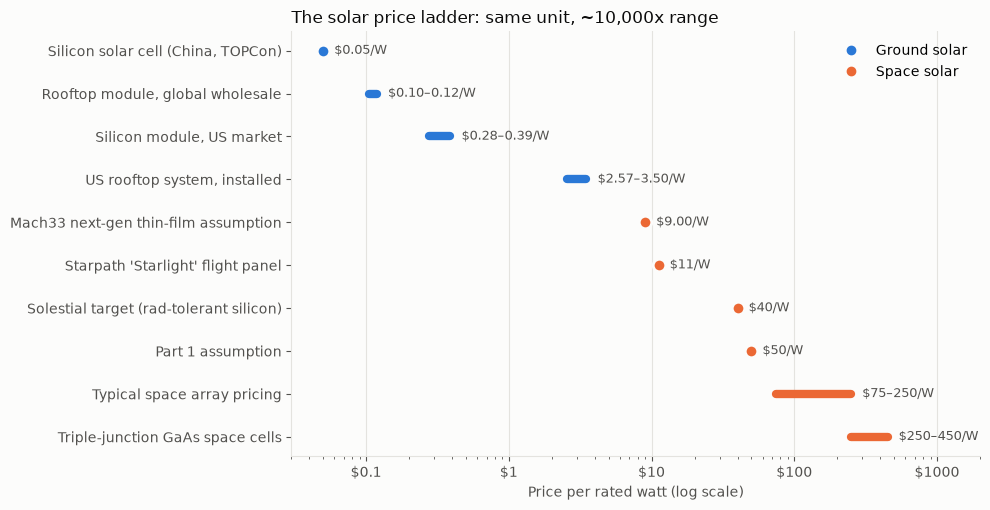

,Item,Low $/W,High $/W,What's included,Source
0,"Silicon solar cell (China, TOPCon)",0.05,0.05,"bare cell, no glass or frame","pv magazine, May 2026"
1,"Rooftop module, global wholesale",0.10,0.12,cells + glass + frame + junction box,"OPIS / InfoLink, Jul 2026"
2,"Silicon module, US market",0.28,0.39,"module, US prices (tariffs)",Surrey review / Anza Q4 2025
3,"US rooftop system, installed",2.57,3.50,modules + inverter + racking + labor + permits,EnergySage H1 2026; LBNL
4,Mach33 next-gen thin-film assumption,9.00,9.00,space array (analyst assumption),Mach33 via secondary
5,Starpath 'Starlight' flight panel,11.20,11.20,space-rated silicon panel,Starpath / TechCrunch 2025
6,Solestial target (rad-tolerant silicon),40.00,40.00,complete 50 kW-class wing (target),NASA SBIR 2023
7,Part 1 assumption,50.00,50.00,complete wing,Part 1
8,Typical space array pricing,75.00,250.00,"complete flight wing, multi-junction",Starpath / TechCrunch 2025
9,Triple-junction GaAs space cells,250.00,450.00,bare cells only,"Surrey review, Acta Astronautica 2026"


In [4]:
# (label, low $/W, high $/W, what it includes, source)
price_ladder = [
    ("Silicon solar cell (China, TOPCon)",          0.05,  0.05,  "bare cell, no glass or frame",                    "pv magazine, May 2026"),
    ("Rooftop module, global wholesale",            0.104, 0.119, "cells + glass + frame + junction box",            "OPIS / InfoLink, Jul 2026"),
    ("Silicon module, US market",                   0.275, 0.39,  "module, US prices (tariffs)",                     "Surrey review / Anza Q4 2025"),
    ("US rooftop system, installed",                2.57,  3.50,  "modules + inverter + racking + labor + permits",  "EnergySage H1 2026; LBNL"),
    ("Mach33 next-gen thin-film assumption",        9.0,   9.0,   "space array (analyst assumption)",                "Mach33 via secondary"),
    ("Starpath 'Starlight' flight panel",           11.2,  11.2,  "space-rated silicon panel",                       "Starpath / TechCrunch 2025"),
    ("Solestial target (rad-tolerant silicon)",     40.0,  40.0,  "complete 50 kW-class wing (target)",              "NASA SBIR 2023"),
    ("Part 1 assumption",                           50.0,  50.0,  "complete wing",                                   "Part 1"),
    ("Typical space array pricing",                 75.0,  250.0, "complete flight wing, multi-junction",            "Starpath / TechCrunch 2025"),
    ("Triple-junction GaAs space cells",            250.0, 450.0, "bare cells only",                                 "Surrey review, Acta Astronautica 2026"),
]
ladder = pd.DataFrame(price_ladder, columns=["Item", "Low $/W", "High $/W", "What's included", "Source"])
ladder["Mid $/W"] = np.sqrt(ladder["Low $/W"] * ladder["High $/W"])

fig, ax = plt.subplots(figsize=(10, 5.2))
y = np.arange(len(ladder))[::-1]
is_space = ladder["What's included"].str.contains("space|wing|flight|cells only|Part")
for yi, (_, r), space in zip(y, ladder.iterrows(), is_space):
    color = SERIES[1] if space else SERIES[0]
    if r["High $/W"] > r["Low $/W"]:
        ax.plot([r["Low $/W"], r["High $/W"]], [yi, yi], color=color, lw=6, solid_capstyle="round")
    else:
        ax.plot(r["Mid $/W"], yi, "o", color=color, ms=9, mec="#fcfcfb", mew=2)
    fmt = lambda v: f"{v:,.2f}" if v < 10 else f"{v:,.0f}"
    label = f"${fmt(r['Low $/W'])}"
    if r["High $/W"] > r["Low $/W"]:
        label += f"–{fmt(r['High $/W'])}"
    ax.annotate(label + "/W", (r["High $/W"], yi), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
ax.set_xscale("log")
ax.set_xlim(0.03, 2_000)
ax.set_yticks(y, ladder["Item"])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:g}"))
ax.set_xlabel("Price per rated watt (log scale)")
ax.set_title("The solar price ladder: same unit, ~10,000x range", loc="left")
ax.plot([], [], "o", color=SERIES[0], label="Ground solar")
ax.plot([], [], "o", color=SERIES[1], label="Space solar")
ax.legend(loc="upper right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

display(ladder[["Item", "Low $/W", "High $/W", "What's included", "Source"]])

#### What sits between a \$0.05 cell and a \$40–250 flight wing

Here is each layer of a space array next to its rooftop equivalent. **No layer-by-layer price breakdown for space arrays has been published**, so this table shows *where* the money goes without inventing numbers for each layer.

| Layer | On your roof | On a satellite | Why the space version costs more |
|---|---|---|---|
| **1. Photovoltaic cells** | Silicon, ~\$0.05/W | Usually triple-junction GaAs (\$250–450/W); Starlink-style designs use silicon | GaAs cells are more efficient and radiation-hard, but are made in tiny volumes on costly germanium wafers |
| **2. Front protection** | 3.2 mm tempered glass sheet, heavy and cheap | Thin (~0.1 mm) cerium-doped **coverglass bonded cell by cell** | Blocks radiation and UV. The Surrey review finds coverglass is **the largest cost in a silicon space array** |
| **3. Wiring** | Soldered ribbons and a junction box | Welded interconnects, bypass diodes, and a harness built to survive tens of thousands of hot–cold cycles | No repair visit is possible |
| **4. Backing structure** | Aluminum frame, ~20 W/kg | Kapton blanket or composite panel, 100–200 W/kg | Getting 10× lighter means exotic materials and careful handling |
| **5. Deployment** | Installer bolts it to a rack | Booms, hinges, and tensioning that unfold once, unattended, after launch shaking | A failed deployment loses the whole satellite |
| **6. Pointing and power transfer** | Fixed tilt | Solar array drive with rotating electrical joints (slip rings) | In a dawn-dusk orbit the Sun barely moves relative to the satellite, so this can be simple |
| **7. Testing and qualification** | One certification per product line | Thermal vacuum, radiation, vibration, and acoustic tests, plus lot acceptance | Small production runs carry the full test cost |
| **8. Volume** | Hundreds of gigawatts made per year | A tiny fraction of that | No economies of scale, yet |

### 1.4 A bookend: what if a space array cost what rooftop solar costs?

To see how far array prices would have to fall, this notebook carries one deliberately extreme case: **a whole deployed space wing priced like a wholesale rooftop module, about \$0.11/W**. It is not a real product. It's a lower bound that answers "if the array were nearly free, what would still stand in the way?"

How far is that from today?

- **Cells are already there.** Silicon cells cost ~\$0.05/W, and some low-cost space-array concepts (Starlink-style) aim to use high-volume terrestrial-grade silicon rather than space-grade GaAs.
- **The rest of the wing is not.** A \$0.11/W wing is ~100× below today's cheapest flight panel (\$11.20/W) and ~360× below Solestial's target. Layers 2–8 in the table above would all have to fall the way rooftop modules did over two decades. Nobody has published a path to this.

### 1.5 Two ways to turn \$/W into something comparable

- **Launch cost per watt** = launch \$/kg ÷ array W/kg. This is how mass becomes money.
- **Array cost per kWh it will ever produce** = \$/W ÷ (kWh produced per W per year × years of life). This compares the array with a power bill.

In [5]:
house_installed_per_w = 2.57
house_lifetime_kwh_per_w = HOUSE_KWH_PER_W_PER_YR * HOUSE_PANEL_LIFE_YR
space_lifetime_kwh_per_w = space_kwh_per_wAM0_yr * SATELLITE_LIFE_YR * (1 - ARRAY_DEGRADATION_PER_YR * SATELLITE_LIFE_YR / 2)

rows = [
    ("Rooftop system, installed",              house_installed_per_w, None,                     house_lifetime_kwh_per_w),
    ("Rooftop module, launched to space",      0.11,  HOUSE_PANEL_W_PER_KG,                     space_lifetime_kwh_per_w),
    ("Space array at rooftop price ($0.11/W)", ROOFTOP_ARRAY_COST_PER_W, ARRAY_SPECIFIC_POWER_W_PER_KG,            space_lifetime_kwh_per_w),
    ("Space array, optimistic default",        ARRAY_COST_PER_W, ARRAY_SPECIFIC_POWER_W_PER_KG, space_lifetime_kwh_per_w),
    ("Space array, Solestial target",          40.0,  200.0,                                    space_lifetime_kwh_per_w),
    ("Space array, roll-out GaAs (ROSA-class)",100.0, 110.0,                                    space_lifetime_kwh_per_w),
]
out = []
for name, price, w_per_kg, kwh in rows:
    launch_per_w = (LAUNCH_COST_PER_KG / w_per_kg) if w_per_kg else 0.0
    total_per_w = price + launch_per_w
    out.append({
        "Option": name,
        "Hardware $/W": price,
        f"Launch $/W @ ${LAUNCH_COST_PER_KG:,.0f}/kg": launch_per_w,
        "Hardware + launch $/W": total_per_w,
        "Lifetime kWh per W": kwh,
        "Array $ per lifetime kWh": total_per_w / kwh,
    })
solar_compare = pd.DataFrame(out)
display(solar_compare)
print(f"For reference, US datacenter electricity is ~$0.06–0.25/kWh (Suncatcher §4.4).")
print(f"Space lifetime = {SATELLITE_LIFE_YR:.0f} yr; rooftop lifetime = {HOUSE_PANEL_LIFE_YR} yr.")
print("'Rooftop module launched to space' ignores that it would not survive (no radiation protection,")
print("outgassing, no deployment). It is there to show that at cheap launch, mass stops mattering.")

,Option,Hardware $/W,Launch $/W @ $100/kg,Hardware + launch $/W,Lifetime kWh per W,Array $ per lifetime kWh
0,"Rooftop system, installed",2.57,0.00,2.57,35.00,0.07
1,"Rooftop module, launched to space",0.11,5.00,5.11,39.72,0.13
2,Space array at rooftop price ($0.11/W),0.11,0.50,0.61,39.72,0.02
3,"Space array, optimistic default",10.00,0.50,10.50,39.72,0.26
4,"Space array, Solestial target",40.00,0.50,40.50,39.72,1.02
5,"Space array, roll-out GaAs (ROSA-class)",100.00,0.91,100.91,39.72,2.54


For reference, US datacenter electricity is ~$0.06–0.25/kWh (Suncatcher §4.4).
Space lifetime = 5 yr; rooftop lifetime = 25 yr.
'Rooftop module launched to space' ignores that it would not survive (no radiation protection,
outgassing, no deployment). It is there to show that at cheap launch, mass stops mattering.


**What this table shows:**
- At Starship-era launch prices, **launch adds only about \$0.50 per watt** to a 200 W/kg array. A 10× heavier rooftop module adds ~\$5/W. **Once launch is cheap, the array's purchase price dominates, not its weight.** This sharpens the Part 1 thesis: with cheap launch, solar arrays become a *parts-cost* problem.
- A space array lives ~5 years (the GPU refresh cycle), while a rooftop system lives ~25. So even though each space watt makes ~6× more energy per year, it gets only a fifth as many years to pay itself back.
- **At \$10/W, the array alone costs about as much per kWh as the *most expensive* datacenter grid power (\$0.25/kWh), before radiators, structure, launch, or the satellite itself.** At \$40/W it is ~4× that. At rooftop prices it is nearly free. That is the central tension of this notebook.

---
## 2. Where Part 1's \$37B actually went

Part 1 reported the space premium, but not *which subsystem* was responsible for it. Here it is broken down.

**Method.** A subsystem's true cost is its hardware price **plus** the launch cost of its mass **plus** its share of the bus. The bus was a flat 25% of total mass, so every kilogram of payload brought 1/0.75 = 1.33 kg to orbit. The values below are copied from Part 1's final scenario: 7,000 km, \$5,453/kg delivered, rerun on 2026-11-15.

,Subsystem,Mass kg,Hardware $M,Launch share $M,Total $M,Share of premium
0,Solar arrays,660.00,6.60,4.80,11.40,0.54
1,Compute (launch only),750.00,0.00,5.45,5.45,0.26
2,Radiators,475.71,0.48,3.46,3.93,0.18
3,Bus fixed cost,0.00,0.50,0.00,0.50,0.02


Per-satellite premium: $21.29M  (Part 1 reported $21.29M)
Fleet premium:         $37.25B (Part 1 reported $37.25B)
Per kW-yr of compute over 5 yr: $37,213/kW-yr


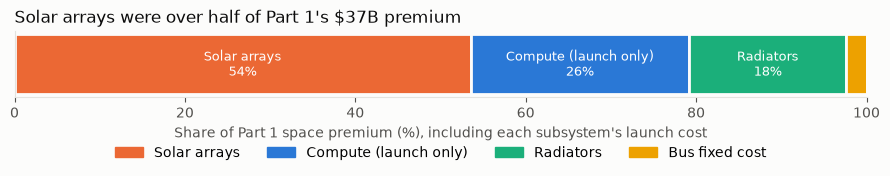

In [6]:
P1 = dict(
    n_sats=1750, alt_km=7000, launch_per_kg=5_453.0, f_sun=0.953,
    m_compute=750.0, m_rad=475.71, m_array=660.0, m_bus=628.57,
    c_compute=2.70e6, c_rad=0.4757e6, c_array=6.60e6, c_bus=0.50e6,
    bus_frac=0.25, avg_compute_kw=114.4,
)
P1["m_total"] = P1["m_compute"] + P1["m_rad"] + P1["m_array"] + P1["m_bus"]
P1["c_launch"] = P1["m_total"] * P1["launch_per_kg"]
gross = 1.0 / (1.0 - P1["bus_frac"])

def p1_row(name, mass, hw):
    launch = mass * gross * P1["launch_per_kg"]
    return {"Subsystem": name, "Mass kg": mass, "Hardware $M": hw / 1e6,
            "Launch share $M": launch / 1e6, "Total $M": (hw + launch) / 1e6}

attr = pd.DataFrame([
    p1_row("Solar arrays", P1["m_array"], P1["c_array"]),
    p1_row("Compute (launch only)", P1["m_compute"], 0.0),
    p1_row("Radiators", P1["m_rad"], P1["c_rad"]),
    {"Subsystem": "Bus fixed cost", "Mass kg": 0.0, "Hardware $M": P1["c_bus"] / 1e6,
     "Launch share $M": 0.0, "Total $M": P1["c_bus"] / 1e6},
])
attr["Share of premium"] = attr["Total $M"] / attr["Total $M"].sum()
P1["premium"] = attr["Total $M"].sum() * 1e6
P1["premium_per_kw_yr"] = P1["premium"] / (P1["avg_compute_kw"] * SATELLITE_LIFE_YR)

display(attr)
print(f"Per-satellite premium: ${P1['premium']/1e6:.2f}M  (Part 1 reported $21.29M)")
print(f"Fleet premium:         ${P1['premium']*P1['n_sats']/1e9:.2f}B (Part 1 reported $37.25B)")
print(f"Per kW-yr of compute over {SATELLITE_LIFE_YR:.0f} yr: ${P1['premium_per_kw_yr']:,.0f}/kW-yr")

fig, ax = plt.subplots(figsize=(9, 2.6))
left = 0.0
colors = [SERIES[1], SERIES[0], SERIES[2], SERIES[3]]
for (_, r), c in zip(attr.iterrows(), colors):
    w = r["Share of premium"] * 100
    ax.barh(0, w, left=left, color=c, edgecolor="#fcfcfb", linewidth=2, height=0.5)
    if w > 6:
        ax.text(left + w / 2, 0, f"{r['Subsystem']}\n{w:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += w
ax.set_xlim(0, 100); ax.set_yticks([]); ax.grid(False)
ax.set_xlabel("Share of Part 1 space premium (%), including each subsystem's launch cost")
ax.set_title("Solar arrays were over half of Part 1's $37B premium", loc="left")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors], labels=list(attr["Subsystem"]),
          loc="upper center", bbox_to_anchor=(0.5, -0.55), ncol=4)
plt.tight_layout(); plt.show()

**Takeaway:** solar arrays were **over half** of Part 1's space premium, even at Part 1's already-optimistic 200 W/kg and \$50/W. Launching the compute module came second. Radiators were under a fifth. So Part 2 focuses on the arrays.

---
## 3. A best-case orbit: 550 km dawn-dusk sun-synchronous

Part 1 went to 7,000 km to escape Earth's shadow. Part 2 starts from the orbit that Google's Suncatcher, and arguably SpaceX's FCC filing, point to instead.

- **Sun-synchronous** means the orbit is tilted slightly past the poles (~97.6°), so Earth's equatorial bulge swings the orbit plane around once per year, in step with the Sun.
- **Dawn-dusk** means the orbit rides the boundary between day and night. The satellite looks down on sunrise or sunset and almost never passes into Earth's shadow.

Why this is the optimistic case:
- **Sunlight nearly all year**, without paying to climb to 7,000 km.
- **Low radiation.** About 150 rad/yr behind 10 mm of aluminum (Suncatcher). At 7,000 km the satellite sits in the inner Van Allen belt.
- **No transfer stage.** Starship drops the satellite close to where it will operate.

### 3.1 Sunlight over the year

Each day of the year we compute the angle between the Sun and the orbit plane, called beta (β), then apply Part 1's cylindrical-shadow model. With β above about 67° at 550 km there is no eclipse at all.

Sun-synchronous inclination at 550 km: 97.58°
Orbital period: 95.5 min;  no-eclipse threshold: |β| > 67.0°
β over the year: 59.0° to 89.9°
Days per year with any eclipse: 98;  worst eclipse: 21.6 min per orbit
Annual average sunlight fraction: 0.9514   (Part 1 at 7,000 km with its beta mix: 0.953)


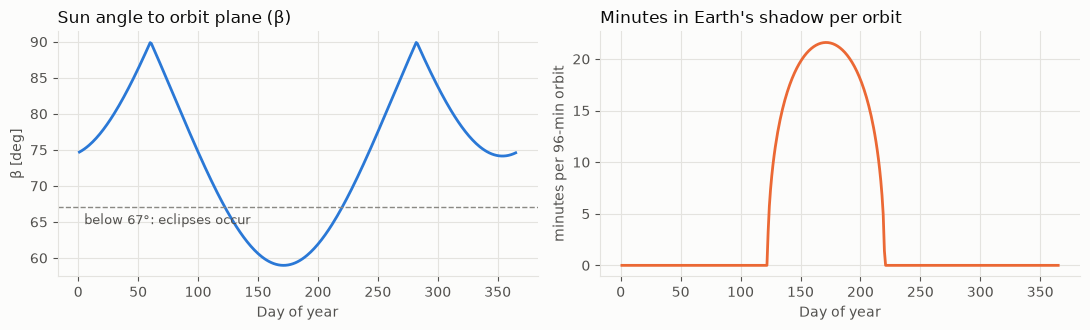

In [7]:
# ---- Functions copied verbatim from Part 1 (space_gpu_datacenter.ipynb, "Core equations") ----
def total_load_w(p_compute_kw: float, overhead_frac: float) -> float:
    """Total electrical load in watts (also treated as heat to reject)."""
    return 1_000.0 * p_compute_kw * (1.0 + overhead_frac)

def orbital_period_s(alt_km: float) -> float:
    r = R_EARTH + 1_000.0 * alt_km
    return 2*np.pi*np.sqrt(r**3 / MU_EARTH)

def sunlight_fraction(alt_km: float, beta_deg: float=0.0) -> float:
    """Fraction of an orbit in sunlight (cylindrical Earth-shadow model). From Part 1."""
    r = R_EARTH + 1_000.0 * alt_km
    beta = np.deg2rad(beta_deg)
    ratio = R_EARTH / r
    if abs(np.sin(beta)) >= ratio:
        return 1.0
    X = (ratio**2 - np.sin(beta)**2) / (np.cos(beta)**2)
    X = np.clip(X, 0.0, 1.0)
    theta_e = np.arcsin(np.sqrt(X))
    return float(1.0 - theta_e/np.pi)

def earth_view_factor_max(alt_km: float) -> float:
    r = R_EARTH + 1_000.0 * alt_km
    return float((R_EARTH / r)**2)

def radiator_area_m2_with_backload(q_internal_w, t_rad_c, alt_km, beta_deg, f_earth=None, f_solar=None):
    """Part 1's radiator sizing (emitted flux minus absorbed Earth IR, albedo, and residual solar),
    condensed to use the global thermal assumptions. Returns (area_m2, net_flux_w_m2).
    Part 2 additions: pass f_earth to override Part 1's Earth view factor (e.g. for a vertical fin),
    and f_solar to override its fixed 2% direct-sunlight factor. Part 1's flat K_EFFECTIVE de-rate is
    replaced by RADIATOR_EFFECTIVENESS, the panel's computed fin efficiency (Section 4)."""
    t_rad_k = t_rad_c + 273.15
    q_emit = EPSILON * SIGMA * RADIATOR_EFFECTIVENESS * (t_rad_k**4 - T_SINK_K**4)
    f_sun = sunlight_fraction(alt_km, beta_deg)
    if f_earth is None:
        f_earth = float(np.clip(earth_view_factor_max(alt_km) * EARTH_VIEW_FRACTION_OF_MAX, 0.0, 1.0))
    q_ir = ALPHA_IR * EARTH_IR_FLUX_W_PER_M2 * f_earth
    q_albedo = ALPHA_SOLAR * SOLAR_CONSTANT * EARTH_BOND_ALBEDO * f_earth * ALBEDO_GEOMETRY_FACTOR * f_sun
    q_solar = ALPHA_SOLAR * SOLAR_CONSTANT * (RADIATOR_SOLAR_VIEW_FACTOR if f_solar is None else f_solar) * f_sun
    q_net = q_emit - (q_ir + q_albedo + q_solar)
    return (np.inf if q_net <= 0 else q_internal_w / q_net), q_net

# ---- New in Part 2: sun-synchronous geometry ----
def sso_inclination_deg(alt_km: float) -> float:
    """Inclination at which J2 precession matches the Sun's yearly motion (360°/365.2422 d)."""
    a = R_EARTH + 1_000.0 * alt_km
    n = math.sqrt(MU_EARTH / a**3)
    omega_dot = 2 * math.pi / (365.2422 * 86_400)
    cos_i = -omega_dot / (1.5 * n * J2 * (R_EARTH / a)**2)
    return math.degrees(math.acos(cos_i))

def sso_beta_deg(day_of_year: float, alt_km: float, ltan_hours: float) -> float:
    """Sun-to-orbit-plane angle for a sun-synchronous orbit with a given local time of ascending node."""
    eps = math.radians(OBLIQUITY_DEG)
    lam = math.radians(360.0 * (day_of_year - 80.0) / 365.2422)       # Sun's ecliptic longitude (0 at ~Mar 21)
    s = np.array([math.cos(lam), math.cos(eps) * math.sin(lam), math.sin(eps) * math.sin(lam)])
    ra_sun = math.atan2(s[1], s[0])
    raan = ra_sun + math.radians(15.0 * (ltan_hours - 12.0))           # node sits (LTAN−12h) east of the Sun
    inc = math.radians(sso_inclination_deg(alt_km))
    n_hat = np.array([math.sin(inc) * math.sin(raan), -math.sin(inc) * math.cos(raan), math.cos(inc)])
    return math.degrees(math.asin(float(np.clip(s @ n_hat, -1, 1))))

INC_DEG = sso_inclination_deg(ALT_KM)
T_ORBIT_MIN = orbital_period_s(ALT_KM) / 60
BETA_CRIT_DEG = math.degrees(math.asin(R_EARTH / (R_EARTH + 1_000 * ALT_KM)))

days = np.arange(1, 366)
betas = np.array([sso_beta_deg(d, ALT_KM, LTAN_HOURS) for d in days])
fsun = np.array([sunlight_fraction(ALT_KM, b) for b in betas])
eclipse_min = (1 - fsun) * T_ORBIT_MIN

F_SUN_ANNUAL = float(fsun.mean())
ECLIPSE_DAYS = int((fsun < 1).sum())

print(f"Sun-synchronous inclination at {ALT_KM:.0f} km: {INC_DEG:.2f}°")
print(f"Orbital period: {T_ORBIT_MIN:.1f} min;  no-eclipse threshold: |β| > {BETA_CRIT_DEG:.1f}°")
print(f"β over the year: {betas.min():.1f}° to {betas.max():.1f}°")
print(f"Days per year with any eclipse: {ECLIPSE_DAYS};  worst eclipse: {eclipse_min.max():.1f} min per orbit")
print(f"Annual average sunlight fraction: {F_SUN_ANNUAL:.4f}   (Part 1 at 7,000 km with its beta mix: 0.953)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(days, betas, color=SERIES[0])
axes[0].axhline(BETA_CRIT_DEG, color=MUTED, lw=1, ls="--")
axes[0].annotate(f"below {BETA_CRIT_DEG:.0f}°: eclipses occur", (5, BETA_CRIT_DEG), xytext=(0, -12),
                 textcoords="offset points", color=INK_2, fontsize=9)
axes[0].set_title("Sun angle to orbit plane (β)", loc="left")
axes[0].set_xlabel("Day of year"); axes[0].set_ylabel("β [deg]")
axes[1].plot(days, eclipse_min, color=SERIES[1])
axes[1].set_title("Minutes in Earth's shadow per orbit", loc="left")
axes[1].set_xlabel("Day of year"); axes[1].set_ylabel(f"minutes per {T_ORBIT_MIN:.0f}-min orbit")
plt.tight_layout(); plt.show()

**Takeaway:** a dawn-dusk orbit is *not* permanently sunlit at 550 km. For about three months around one solstice, the Sun angle drops below the ~67° threshold, and the satellite crosses Earth's shadow on every orbit, for up to ~20 minutes. Under the sunlight-only design (no batteries; compute pauses in shadow), that costs **about 5% of yearly output**. The result is **about the same sunlight as Part 1 got at 7,000 km** (95.3%), but without the expensive climb or the radiation belts.

(Higher dawn-dusk orbits shrink the eclipse season: the shadow threshold drops as altitude rises. Batteries sized for ~20 minutes could also bridge it. Both are possible refinements.)

### 3.2 Radiation (summary; details in `research/part2_research.md`)
- **550 km SSO:** ~150 rad(Si)/yr behind 10 mm Al, so ~750 rad over 5 years. Google's Trillium TPUs showed memory (HBM) irregularities only at ~2 krad and no hard failures up to 15 krad. **GPUs plausibly survive.**
- **Solar cells:** taken optimistically at **1%/yr** power loss for annealing silicon. Solestial lab data showed 96% voltage retained after a 10-year-LEO-equivalent dose.
- **7,000 km:** inner-belt protons that are very hard to shield. Both the GPUs and the arrays become a real problem. This is one of the costs of "going higher" (Section 11).

### 3.3 Drag: why a huge satellite at 550 km can still be cheap to keep up

At 550 km there is still a trace of atmosphere, and a satellite with hundreds of m² of panels would normally feel strong drag. **But in a dawn-dusk orbit, the Sun sits roughly perpendicular to the orbit plane.** So:
- the **solar arrays** face sideways, toward the Sun, and present their thin edge to the direction of travel;
- the **radiators** are the harder case. They must stay edge-on to the Sun, and at 550 km they also want to avoid facing Earth's hot surface. They can't be edge-on to the Sun, edge-on to the airflow, *and* turned away from Earth all at once. Section 4.1 works through the two practical layouts; we choose **vertical fins that face the airflow (layout B)** because the extra drag turns out to be cheap.

### 3.4 The Sun is rarely exactly side-on

Section 3.1 showed β swinging between about 59° and 90° over the year. Only at β = 90° does the Sun sit exactly along the orbit normal. The rest of the time it is tilted by up to ~31°, and because the satellite keeps one face toward Earth, that tilt circles around the satellite once per orbit. Two things follow:

- **Solar arrays.** A wing fixed facing the orbit normal catches sunlight at an angle and makes less power: 14% less on the worst day. We take the optimistic fix. Each wing **rolls about its long axis** to follow the Sun, which removes about half of the loss and keeps the wing edge-on to the airflow (Section 3.3). The alternative is a bigger array.
- **Radiators.** A fin can't stay perfectly edge-on to the Sun. Sunlight grazes one face, and the radiator must be big enough to reject that heat too. Part 1 assumed 2% of full sunlight. Here it is computed from the geometry.

When the array makes less than the full load, compute throttles to match. **Availability** below is the year-average fraction of full compute power, counting both shadow and off-angle sunlight. It replaces the plain sunlight fraction from here on.


In [8]:
ORBIT_ANGLE = np.linspace(0, 2 * np.pi, 720, endpoint=False)   # position around the orbit; 0 = the point nearest the Sun

def sun_around_orbit(beta_deg: float):
    """Sun direction in satellite axes at each point of one orbit, and whether the satellite is sunlit.
    Returns (part toward travel X, part toward zenith Y, part toward the orbit normal Z, sunlit).
    The orbit-normal part is constant (sin β). The rest (cos β) swings between zenith and the
    direction of travel once per orbit, because the satellite keeps one face toward Earth."""
    beta = math.radians(beta_deg)
    s_x, s_y = math.cos(beta) * np.sin(ORBIT_ANGLE), math.cos(beta) * np.cos(ORBIT_ANGLE)
    s_z = np.full_like(ORBIT_ANGLE, math.sin(beta))
    # Same cylindrical shadow as sunlight_fraction(): in shadow when on the night side and
    # closer to the Earth–Sun line than one Earth radius.
    in_shadow = (s_y < 0) & (np.sqrt(1 - s_y**2) < R_EARTH / (R_EARTH + 1_000 * ALT_KM))
    return s_x, s_y, s_z, ~in_shadow

def array_sun_factor(s_y, s_z, tracking: str):
    """Fraction of rated power the array makes, set by the angle of the sunlight on it.
    "fixed": wings face the orbit normal. "one-axis": each wing also rolls about its long
    axis (the direction of travel) to face the Sun as nearly as it can."""
    return s_z if tracking == "fixed" else np.sqrt(s_y**2 + s_z**2)

@lru_cache(maxsize=None)
def compute_availability(tracking: str = ARRAY_SUN_TRACKING, oversize: float = ARRAY_OVERSIZE) -> float:
    """Year-average fraction of full compute power. Compute pauses in shadow, and throttles
    whenever the array makes less than the full load."""
    daily = []
    for b in betas:
        _, s_y, s_z, sunlit = sun_around_orbit(b)
        daily.append((sunlit * np.minimum(1.0, oversize * array_sun_factor(s_y, s_z, tracking))).mean())
    return float(np.mean(daily))

@lru_cache(maxsize=None)
def radiator_sun_factor(layout: str) -> float:
    """Direct sunlight absorbed by the radiator, as a fraction of head-on sunlight per m² of
    radiating surface. Averaged over the sunlit part of an orbit, on the worst day of the year.
    Layout B: fins face ±X, so one of the two faces is lit. Layout A: the one face looks at zenith."""
    worst = 0.0
    for b in betas:
        s_x, s_y, _, sunlit = sun_around_orbit(b)
        on_faces = np.abs(s_x) / 2 if layout == "B" else np.clip(s_y, 0, None)
        worst = max(worst, float(on_faces[sunlit].mean()))
    return worst

AVAILABILITY = compute_availability()

oversize_opts = [1.0, 1.05, 1.10, 1 / math.sin(math.radians(betas.min()))]
avail = pd.DataFrame(
    {name: [compute_availability(t, k) for k in oversize_opts]
     for name, t in [("Fixed wings", "fixed"), ("Wings roll to follow the Sun", "one-axis")]},
    index=pd.Index([f"{k - 1:+.0%}" for k in oversize_opts], name="Extra array"),
)
print("Availability: year-average fraction of full compute power")
display(avail.style.format("{:.1%}"))
print(f"Sunlight fraction alone: {F_SUN_ANNUAL:.1%}.  Chosen: {ARRAY_SUN_TRACKING} wings, {ARRAY_OVERSIZE - 1:+.0%} array "
      f"-> availability {AVAILABILITY:.1%}")
print(f"Direct sunlight on the radiator, worst day, per m² of radiating surface: layout B {radiator_sun_factor('B'):.1%}, "
      f"layout A {radiator_sun_factor('A'):.1%} of full sunlight (Part 1 assumed {RADIATOR_SOLAR_VIEW_FACTOR:.0%})")


Availability: year-average fraction of full compute power


,Fixed wings,Wings roll to follow the Sun
Extra array,,
+0%,90.8%,92.8%
+5%,93.4%,94.4%
+10%,94.5%,94.9%
+17%,95.1%,95.1%


Sunlight fraction alone: 95.1%.  Chosen: one-axis wings, +0% array -> availability 92.8%
Direct sunlight on the radiator, worst day, per m² of radiating surface: layout B 18.6%, layout A 21.2% of full sunlight (Part 1 assumed 2%)


**Takeaway:** off-angle sunlight costs about as much output as Earth's shadow does.
- With wings that roll to follow the Sun, availability is **~93%**, against the 95% that shadow alone would give. Fixed wings would give ~91%.
- Making the array ~17% bigger would recover all of it. But the array is the most expensive part of the satellite, so throttling for a few weeks a year is the cheaper choice.
- In the worst season the radiator absorbs **about ten times more direct sunlight** than Part 1's 2%. Section 4 sizes it for that, which adds ~10% to its area.


---
## 4. Sizing one best-case satellite

The satellite carries the same 120 kW compute module as Part 1. What changes:

- **Array** sized for *end-of-life* power: it must still deliver the full load in head-on sunlight after 5 years at 1%/yr degradation. In off-angle sunlight, compute throttles (Section 3.4).
- **Radiator** sized at 550 km with Part 1's thermal model, for full load on the day when the most sunlight grazes its faces. Its mass and efficiency now come from a detailed panel design (next).
- **No batteries.** Sunlight-only operation, as in Part 1.
- **Station-keeping propellant** for drag over the satellite's life, using electric propulsion.
- **Launch** at Starship \$/kg straight to 550 km, so there is no transfer stage.
- **Bus** still a flat 25% of total mass. Section 10 replaces this with a bottom-up bus from the SolidWorks model.

#### The radiator panel, designed rather than assumed

Part 1 charged the radiator a flat **2.0 kg per m²** of radiating surface and a flat 10% performance de-rate (`K_EFFECTIVE = 0.90`). To check both, I designed one of the satellite's eight radiator panels in SolidWorks (`cad/radiator/`, including a toleranced engineering drawing). It is a 4.6 × 4.7 m aluminum honeycomb sandwich, 25 mm thick, with 30 ammonia flow tubes bonded between the face sheets at 150 mm spacing. Two numbers come out of it:

- **Mass.** The panel weighs **93 kg** with coolant, adhesive, and paint. Both faces radiate, so that is **2.18 kg per m² of radiating surface**: 9% above the 2.0 assumed, and still *without* pumps and the flex hoses across the hinges (left out, optimistically).
- **Fin efficiency.** Heat enters the thin face sheet only at the tubes and has to spread sideways. The sheet midway between tubes runs cooler, and because radiation goes as $T^4$, it sheds less heat. The strip between two tubes is a textbook fin:
  $$\eta_{fin} = \frac{\tanh(mL)}{mL},\qquad m = \sqrt{\frac{h_{rad}}{k\,t}},\qquad h_{rad} = 4\varepsilon\sigma T^3$$
  with $t$ the sheet thickness, $k$ its conductivity, and $L$ half the gap between tube flanges. Averaged with the flanges themselves, the panel radiates only **~80%** as much as an ideal isothermal plate. This replaces Part 1's generic 0.90. Part 2 already computes the Earth and Sun view factors explicitly, so keeping both de-rates would double count.

The ~20% shortfall means ~25% more radiator area. That in turn needs eight panels instead of six, which makes the folded stack taller (Section 10).

Could a better panel avoid this? The sweep below varies sheet thickness and tube spacing, using the CAD model's mass breakdown. Thicker sheets or more tubes raise the efficiency, but they add mass faster than they add heat rejection. The best combination is only ~5% lighter per *effective* m² than the panel I drew, and it needs an impractically thin 0.15 mm sheet. **The ~20% penalty comes with this kind of panel; it is not a sign of a weak design.**

In [9]:
import json, os

def radiator_fin_efficiency(skin_t_m=RADIATOR_SKIN_THICKNESS_M, pitch_m=RADIATOR_TUBE_PITCH_M,
                            flange_m=RADIATOR_TUBE_FLANGE_M, k=RADIATOR_SKIN_K_W_PER_MK,
                            t_rad_c=T_GPU_C - DELTA_T_TO_RADIATOR_C) -> float:
    """Surface efficiency of a tube-and-sheet radiator face. Flanges sit at the tube temperature; the sheet
    between flanges is a straight fin, insulated at the midpoint (by symmetry), radiating from one side
    with the linearized coefficient h_rad = 4·ε·σ·T³."""
    h_rad = 4 * EPSILON * SIGMA * (t_rad_c + 273.15) ** 3
    half_gap = (pitch_m - flange_m) / 2
    mL = math.sqrt(h_rad / (k * skin_t_m)) * half_gap
    return (flange_m + 2 * half_gap * math.tanh(mL) / mL) / pitch_m

RADIATOR_EFFECTIVENESS = radiator_fin_efficiency()
print(f"Fin efficiency of the drawn panel: {RADIATOR_EFFECTIVENESS:.3f}  (Part 1's flat de-rate: {K_EFFECTIVE:.2f})")
print(f"Effective mass per m² of ideal radiating surface: {RADIATOR_AREAL_DENSITY / RADIATOR_EFFECTIVENESS:.2f} kg  "
      f"(Part 1: {2.0 / K_EFFECTIVE:.2f} kg)")

# Sweep sheet thickness and tube spacing, holding everything else in the CAD mass roll-up fixed.
cad_mass_path = "cad/radiator/mass.json"
if not os.path.exists(cad_mass_path):
    print(f"{cad_mass_path} not found: run cad/radiator/build_radiator.py with SolidWorks open for the sweep.")
else:
    with open(cad_mass_path) as f:
        cad_rad = json.load(f)
    panel_l, panel_w = (v / 1000 for v in cad_rad["panel_mm"][:2])  # [CAD] panel planform [m]
    planform = panel_l * panel_w
    print(f"CAD check: {cad_rad['total_kg']:.1f} kg per panel = "
          f"{cad_rad['total_kg'] / (2 * planform):.2f} kg per radiating m² (assumption above: {RADIATOR_AREAL_DENSITY})")
    rho_skin = 2_810.0                                             # 7075 aluminum [kg/m³]
    tube_kg_per_m = cad_rad["parts_kg"]["flow_tube"] / panel_w     # one flow tube extrusion, per meter of tube
    skins = 2 * RADIATOR_SKIN_THICKNESS_M * rho_skin
    rest = cad_rad["total_kg"] / planform - skins - tube_kg_per_m / RADIATOR_TUBE_PITCH_M  # core, closeouts, coolant, ...

    def kg_per_effective_m2(skin_t_m, pitch_m):
        planform_kg = 2 * skin_t_m * rho_skin + tube_kg_per_m / pitch_m + rest
        return planform_kg / (2 * radiator_fin_efficiency(skin_t_m, pitch_m))

    skins_mm = [0.15, 0.25, 0.40, 0.60]
    pitches_mm = [100, 125, 150, 200, 250, 300]
    sweep = pd.DataFrame([[kg_per_effective_m2(t / 1e3, p / 1e3) for p in pitches_mm] for t in skins_mm],
                         index=[f"{t:.2f} mm sheet" for t in skins_mm],
                         columns=[f"{p} mm pitch" for p in pitches_mm])
    best = sweep.stack().idxmin()
    print(f"kg per effective m² of radiating surface (drawn panel: 0.25 mm, 150 mm = "
          f"{kg_per_effective_m2(RADIATOR_SKIN_THICKNESS_M, RADIATOR_TUBE_PITCH_M):.2f}; "
          f"best in sweep: {best[0]}, {best[1]} = {sweep.stack().min():.2f})")
    display(sweep.round(2))


Fin efficiency of the drawn panel: 0.796  (Part 1's flat de-rate: 0.90)
Effective mass per m² of ideal radiating surface: 2.74 kg  (Part 1: 2.22 kg)
CAD check: 93.3 kg per panel = 2.18 kg per radiating m² (assumption above: 2.18)
kg per effective m² of radiating surface (drawn panel: 0.25 mm, 150 mm = 2.74; best in sweep: 0.15 mm sheet, 125 mm pitch = 2.60)


,100 mm pitch,125 mm pitch,150 mm pitch,200 mm pitch,250 mm pitch,300 mm pitch
0.15 mm sheet,2.63,2.60,2.66,2.94,3.33,3.76
0.25 mm sheet,2.81,2.72,2.74,2.93,3.26,3.65
0.40 mm sheet,3.17,3.05,3.03,3.17,3.44,3.80
0.60 mm sheet,3.69,3.56,3.52,3.62,3.86,4.19


In [10]:
def drag_dv_per_yr(mass_kg: float, frontal_area_m2: float) -> float:
    """Δv per year to cancel drag [m/s/yr] = drag deceleration × seconds per year."""
    v = math.sqrt(MU_EARTH / (R_EARTH + 1_000 * ALT_KM))
    accel = 0.5 * ATM_DENSITY_KG_M3 * v**2 * DRAG_CD * frontal_area_m2 / mass_kg
    return accel * 365.25 * 86_400

def sso_payload_factor() -> float:
    """Fraction of due-east LEO payload Starship carries to a ~98° sun-synchronous orbit. [EST]
    A due-east launch from 26°N borrows Earth's rotation; a near-polar retrograde launch must
    instead cancel a little of it. The extra Δv is charged to the ship via the rocket equation."""
    v_rot = 465.1 * math.cos(math.radians(LAUNCH_SITE_LAT_DEG))
    sin_az = math.cos(math.radians(INC_DEG)) / math.cos(math.radians(LAUNCH_SITE_LAT_DEG))
    extra_dv = v_rot - v_rot * sin_az                      # lose the eastward boost, plus fight a bit of it
    ve = SHIP_ISP_VAC_S * G0
    p0 = STARSHIP_PAYLOAD_LEO_T
    dv0 = ve * math.log((SHIP_DRY_T + SHIP_PROP_T + p0) / (SHIP_DRY_T + p0))
    ratio = math.exp((dv0 + extra_dv) / ve)
    p1 = (SHIP_DRY_T + SHIP_PROP_T - ratio * SHIP_DRY_T) / (ratio - 1)
    return max(p1, 0.0) / p0, extra_dv

SSO_FACTOR, SSO_EXTRA_DV = sso_payload_factor()


def earth_view_factor_vertical_plate(alt_km: float) -> float:
    """View factor from one face of a vertical (horizon-facing) plate to the Earth.
    F = (1/π)·[atan(1/√(H²−1)) − √(H²−1)/H²], with H = r/R_earth."""
    H = (R_EARTH + 1_000 * alt_km) / R_EARTH
    k = math.sqrt(H**2 - 1)
    return (math.atan(1 / k) - k / H**2) / math.pi


def size_satellite(
    launch_cost_per_kg=LAUNCH_COST_PER_KG,
    array_cost_per_w=ARRAY_COST_PER_W,
    array_w_per_kg=ARRAY_SPECIFIC_POWER_W_PER_KG,
    array_degr_per_yr=ARRAY_DEGRADATION_PER_YR,
    life_yr=SATELLITE_LIFE_YR,
    bus_frac=BUS_MASS_FRACTION_OF_TOTAL,
    frontal_area_m2=FRONTAL_AREA_EDGE_ON_M2,
    apply_sso_penalty=APPLY_SSO_PAYLOAD_PENALTY,
    array_oversize=ARRAY_OVERSIZE,
    sun_tracking=ARRAY_SUN_TRACKING,
    radiator_layout=RADIATOR_LAYOUT,
    bus_mass_kg=None,
    sats_per_flight=None,
) -> dict:
    """One satellite at 550 km dawn-dusk. Returns masses [kg], costs [$], and premium metrics."""
    p_load_w = total_load_w(P_COMPUTE_KW, OVERHEAD_FRAC)

    # Solar array: sized so end-of-life power still meets the full load in head-on sunlight
    eol_factor = (1 - array_degr_per_yr) ** life_yr
    p_array_bol_w = p_load_w * array_oversize / eol_factor
    m_array = p_array_bol_w / array_w_per_kg
    a_array = p_array_bol_w / ARRAY_POWER_DENSITY_W_PER_M2
    c_array = p_array_bol_w * array_cost_per_w

    # Radiator: sized for full load while sunlit, on the day of the year when the most sunlight
    # grazes its faces (Section 3.4).
    #   Layout B: vertical fins, both faces radiate, each face sees part of Earth; fins face the airflow.
    #   Layout A: flat zenith-facing panel, one radiating face that never sees Earth; edge-on to the airflow.
    f_earth = earth_view_factor_vertical_plate(ALT_KM) if radiator_layout == "B" else 0.0
    a_rad, q_net = radiator_area_m2_with_backload(p_load_w, T_GPU_C - DELTA_T_TO_RADIATOR_C, ALT_KM, 90.0, f_earth,
                                                  radiator_sun_factor(radiator_layout))
    a_rad_panel = a_rad / (2 if radiator_layout == "B" else 1)    # physical panel (planform) area
    m_rad = a_rad * RADIATOR_AREAL_DENSITY                         # kg per m² of radiating surface
    c_rad = a_rad * RADIATOR_COST_PER_M2
    frontal = frontal_area_m2 + (a_rad_panel if radiator_layout == "B" else 0.0)

    # Dry mass with bus (flat fraction, or a bottom-up bus mass from CAD), then drag propellant
    m_core = M_COMPUTE_KG + m_rad + m_array
    m_dry = m_core / (1 - bus_frac) if bus_mass_kg is None else m_core + bus_mass_kg
    dv_life = drag_dv_per_yr(m_dry, frontal) * life_yr
    m_prop = m_dry * (math.exp(dv_life / (G0 * EP_ISP_S)) - 1)
    m_total = m_dry + m_prop

    # Launch: $/kg × mass, or (with a packing limit) flight price ÷ satellites per flight
    if sats_per_flight is None:
        eff_cost_per_kg = launch_cost_per_kg / (SSO_FACTOR if apply_sso_penalty else 1.0)
        c_launch = m_total * eff_cost_per_kg
    else:
        c_launch = launch_cost_per_kg * STARSHIP_PAYLOAD_LEO_T * 1_000 / sats_per_flight
        eff_cost_per_kg = c_launch / m_total

    premium = c_array + c_rad + BUS_COST_FIXED + c_launch
    # Average compute delivered: paused in shadow, throttled in off-angle sunlight (Section 3.4)
    avg_compute_kw = P_COMPUTE_KW * compute_availability(sun_tracking, array_oversize)
    return dict(
        p_load_kw=p_load_w / 1e3, p_array_bol_kw=p_array_bol_w / 1e3, a_array_m2=a_array, a_rad_m2=a_rad,
        a_rad_panel_m2=a_rad_panel, f_earth=f_earth, frontal_m2=frontal,
        m_compute=M_COMPUTE_KG, m_array=m_array, m_rad=m_rad, m_bus=m_dry - m_core, m_prop=m_prop, m_total=m_total,
        dv_life=dv_life, eff_cost_per_kg=eff_cost_per_kg,
        c_array=c_array, c_rad=c_rad, c_bus=BUS_COST_FIXED, c_launch=c_launch,
        c_compute=P_COMPUTE_KW * COMPUTE_COST_PER_KW,
        premium=premium, avg_compute_kw=avg_compute_kw,
        premium_per_kw_yr=premium / (avg_compute_kw * life_yr),
        premium_per_w_compute=premium / (avg_compute_kw * 1e3),
        gross=m_dry / m_core, life_yr=life_yr,
    )

BEST = size_satellite()

def attribution(s: dict) -> pd.DataFrame:
    """Subsystem cost = hardware + launch of its mass (grossed up for its share of the bus)."""
    k = s["gross"] * s["eff_cost_per_kg"]
    rows = [
        ("Solar arrays",          s["m_array"],   s["c_array"]),
        ("Compute (launch only)", s["m_compute"], 0.0),
        ("Radiators",             s["m_rad"],     s["c_rad"]),
    ]
    df = pd.DataFrame([{"Subsystem": n, "Mass kg": m, "Hardware $M": hw / 1e6,
                        "Launch share $M": m * k / 1e6, "Total $M": (hw + m * k) / 1e6} for n, m, hw in rows])
    extra = pd.DataFrame([
        {"Subsystem": "Bus fixed cost", "Mass kg": 0.0, "Hardware $M": s["c_bus"] / 1e6, "Launch share $M": 0.0, "Total $M": s["c_bus"] / 1e6},
        {"Subsystem": "Drag propellant", "Mass kg": s["m_prop"], "Hardware $M": 0.0,
         "Launch share $M": s["m_prop"] * s["eff_cost_per_kg"] / 1e6, "Total $M": s["m_prop"] * s["eff_cost_per_kg"] / 1e6},
    ])
    df = pd.concat([df, extra], ignore_index=True)
    df["Share of premium"] = df["Total $M"] / df["Total $M"].sum()
    return df

print(f"Load {BEST['p_load_kw']:.0f} kW -> array {BEST['p_array_bol_kw']:.1f} kW at beginning of life "
      f"({BEST['a_array_m2']:.0f} m²), radiator {BEST['a_rad_m2']:.0f} m² radiating = {BEST['a_rad_panel_m2']:.0f} m² of panels")
print(f"Satellite mass {BEST['m_total']:,.0f} kg  (Part 1: {P1['m_total']:,.0f} kg)")
print(f"Lifetime drag Δv {BEST['dv_life']:.1f} m/s -> {BEST['m_prop']:.1f} kg propellant")
print(f"Space premium per satellite: ${BEST['premium']/1e6:.2f}M  (Part 1: ${P1['premium']/1e6:.2f}M)")
display(attribution(BEST))

Load 132 kW -> array 138.8 kW at beginning of life (347 m²), radiator 343 m² radiating = 171 m² of panels
Satellite mass 2,960 kg  (Part 1: 2,514 kg)
Lifetime drag Δv 191.3 m/s -> 38.2 kg propellant
Space premium per satellite: $2.87M  (Part 1: $21.29M)


,Subsystem,Mass kg,Hardware $M,Launch share $M,Total $M,Share of premium
0,Solar arrays,694.01,1.39,0.09,1.48,0.52
1,Compute (launch only),750.00,0.00,0.10,0.10,0.03
2,Radiators,747.05,0.69,0.10,0.78,0.27
3,Bus fixed cost,0.00,0.50,0.00,0.50,0.17
4,Drag propellant,38.24,0.00,0.00,0.00,0.00


### 4.1 Radiator layout: why we chose vertical fins that face the airflow (layout B)

A radiator has to stay **edge-on to the Sun** (or it soaks up sunlight). At 550 km it would also like to **avoid facing Earth**, whose infrared glow is a heat source. And to keep drag low it would like to be **edge-on to the airflow**. In a dawn-dusk orbit, the Sun, the airflow, and the Earth sit along three perpendicular directions, so a flat panel can't satisfy all three. Two practical options:

| | Layout A: flat, facing straight up | Layout B: vertical fins (chosen) |
|---|---|---|
| Orientation | Panel faces zenith; edge-on to Sun and airflow | Fin in the plane of zenith and Sun; faces the airflow |
| Radiating faces | One (the Earth-facing back must be insulated) | Two |
| Sees Earth? | No | Each face sees Earth's limb (view factor ≈ 0.26 at 550 km) |
| Drag | Minimal | Fin area meets the airflow |

Part 1 assumed radiators saw only 10% of the maximum possible Earth view. For a vertical fin that is too optimistic, so layout B uses the proper geometric view factor below.

In [11]:
rows = []
for label, kw in [("A: flat, zenith-facing", dict(radiator_layout="A")),
                  ("B: vertical fins (chosen)", dict(radiator_layout="B")),
                  ("B, with arrays also facing the airflow (worst)", dict(radiator_layout="B", frontal_area_m2=FRONTAL_AREA_EDGE_ON_M2 + BEST["a_array_m2"]))]:
    s = size_satellite(**kw)
    rows.append({"Layout": label, "Earth view factor": s["f_earth"], "Radiating m²": s["a_rad_m2"],
                 "Panel m²": s["a_rad_panel_m2"], "Radiator kg": s["m_rad"], "Frontal m²": s["frontal_m2"],
                 f"Drag Δv over {SATELLITE_LIFE_YR:.0f} yr [m/s]": s["dv_life"], "Propellant kg": s["m_prop"],
                 "Satellite kg": s["m_total"], "Premium $M": s["premium"] / 1e6})
layouts = pd.DataFrame(rows)
display(layouts)
print("Density at 550 km swings ~10× over the solar cycle; the default uses a near-solar-maximum value. [EST]")

,Layout,Earth view factor,Radiating m²,Panel m²,Radiator kg,Frontal m²,Drag Δv over 5 yr [m/s],Propellant kg,Satellite kg,Premium $M
0,"A: flat, zenith-facing",0.00,298.10,298.10,649.87,15.00,16.11,3.06,"2,794.90",2.76
1,B: vertical fins (chosen),0.26,342.68,171.34,747.05,186.34,191.28,38.24,"2,959.66",2.87
2,"B, with arrays also facing the airflow (worst)",0.26,342.68,171.34,747.05,533.35,547.49,110.78,"3,032.20",2.88


Density at 550 km swings ~10× over the solar cycle; the default uses a near-solar-maximum value. [EST]


**Takeaways from the best-case satellite:**
- Moving to 550 km removes Part 1's 2.18× transfer-stage launch penalty. Starship at \$100/kg instead of \$5,453/kg makes **launch nearly disappear from the budget**.
- What remains is **mostly the solar array purchase price**, even at an optimistic \$10/W.
- **Why layout B anyway.** On paper B costs ~3% more per satellite: its fins see Earth, so they need ~13% more radiating area than A, plus ~30 kg of drag propellant over 5 years. But radiating from both faces means **only about half the physical panel area** to build, fold, deploy, and fit into Starship (Section 10 checks the packing). The drag is acceptable: tens of kg of electric-propulsion propellant cost almost nothing at Starship prices.
- Radiator mass and cost are charged per m² of *radiating* surface in both layouts, so a two-sided panel weighs ~4.3 kg per m² of panel (the detailed design), close to the pumped-loop thesis's 3.9 kg/m² planform figure.
- Sunlight grazing the fins (Section 3.4) makes the radiator ~10% bigger than a perfectly edge-on fin would need.
- The solar arrays must stay edge-on to the airflow: the worst case (arrays facing it too) multiplies drag several-fold.

---
## 5. Fleet and the terrestrial yardstick

**What does "viable" mean?** The space fleet has to beat what the same compute costs on the ground, *excluding the GPUs*, which both sides buy. On the ground you pay for:
- the **building**, with power distribution and cooling, and
- the **electricity**.

We express both in **\$/kW-yr of compute**. Following the optimism principle, the ground side is made as expensive as is defensible:
- an AI-ready build at **\$20M/MW**,
- charged entirely to one **5-year** GPU generation (in reality the building outlasts several),
- electricity at **\$1,500/kW-yr**, the middle of \$570–3,000.

That is generous to space, so we also show a **realistic** ground yardstick: an average US build (\$11.7M/MW) spread over a 15-year building life, plus the same electricity.

Sections 5–8 still use the flat 25% bus and assume every Starship flies full by mass. Section 10 replaces both with the SolidWorks model, and Section 10.3 gives the headline numbers.

In [12]:
def terrestrial_per_kw_yr(build_per_mw=TERRESTRIAL_BUILD_COST_PER_MW,
                          amort_yr=TERRESTRIAL_BUILD_AMORTIZATION_YR,
                          energy=TERRESTRIAL_ENERGY_COST_PER_KW_YR) -> float:
    return build_per_mw / 1_000 / amort_yr + energy

TERR = terrestrial_per_kw_yr()   # optimistic for space
TERR_REAL = terrestrial_per_kw_yr(TERRESTRIAL_REALISTIC_BUILD_COST_PER_MW, TERRESTRIAL_REALISTIC_AMORTIZATION_YR)
TERR_LOW = terrestrial_per_kw_yr(10.7e6, 15, TERRESTRIAL_ENERGY_RANGE_PER_KW_YR[0])
TERR_HIGH = terrestrial_per_kw_yr(20e6, 5, TERRESTRIAL_ENERGY_RANGE_PER_KW_YR[1])

n_sats = math.ceil(TARGET_AVG_COMPUTE_MW * 1_000 / BEST["avg_compute_kw"])
fleet = pd.DataFrame([
    ("Satellites for 200 MW average compute", f"{n_sats:,}", f"{P1['n_sats']:,}"),
    ("Mass per satellite", f"{BEST['m_total']:,.0f} kg", f"{P1['m_total']:,.0f} kg"),
    ("Fleet mass", f"{n_sats*BEST['m_total']/1e3:,.0f} t", f"{P1['n_sats']*P1['m_total']/1e3:,.0f} t"),
    ("Fleet space premium", f"${n_sats*BEST['premium']/1e9:,.1f}B", f"${P1['n_sats']*P1['premium']/1e9:,.1f}B"),
    ("Space premium per kW-yr", f"${BEST['premium_per_kw_yr']:,.0f}", f"${P1['premium_per_kw_yr']:,.0f}"),
    ("Ground yardstick, optimistic for space", f"${TERR:,.0f}", f"${TERR:,.0f}"),
    ("Space ÷ optimistic ground", f"{BEST['premium_per_kw_yr']/TERR:.1f}x", f"{P1['premium_per_kw_yr']/TERR:.1f}x"),
    ("Ground yardstick, realistic", f"${TERR_REAL:,.0f}", f"${TERR_REAL:,.0f}"),
    ("Space ÷ realistic ground", f"{BEST['premium_per_kw_yr']/TERR_REAL:.1f}x", f"{P1['premium_per_kw_yr']/TERR_REAL:.1f}x"),
], columns=["Metric", "Part 2 best case (550 km)", "Part 1 (7,000 km)"])
display(fleet)
print(f"Ground yardstick range: ${TERR_LOW:,.0f}/kW-yr (cheap power, 15-yr building) to "
      f"${TERR_HIGH:,.0f}/kW-yr (expensive power, 5-yr building)")

,Metric,Part 2 best case (550 km),"Part 1 (7,000 km)"
0,Satellites for 200 MW average compute,"1,797","1,750"
1,Mass per satellite,"2,960 kg","2,514 kg"
2,Fleet mass,"5,319 t","4,400 t"
3,Fleet space premium,$5.2B,$37.3B
4,Space premium per kW-yr,"$5,154","$37,213"
5,"Ground yardstick, optimistic for space","$5,500","$5,500"
6,Space ÷ optimistic ground,0.9x,6.8x
7,"Ground yardstick, realistic","$2,280","$2,280"
8,Space ÷ realistic ground,2.3x,16.3x


Ground yardstick range: $1,283/kW-yr (cheap power, 15-yr building) to $7,000/kW-yr (expensive power, 5-yr building)


---
## 6. The staircase: from Part 1 to the best case

Each step changes **one** assumption, so you can see which levers matter. Spending is shown per kW-yr of compute and compared with the ground yardstick.

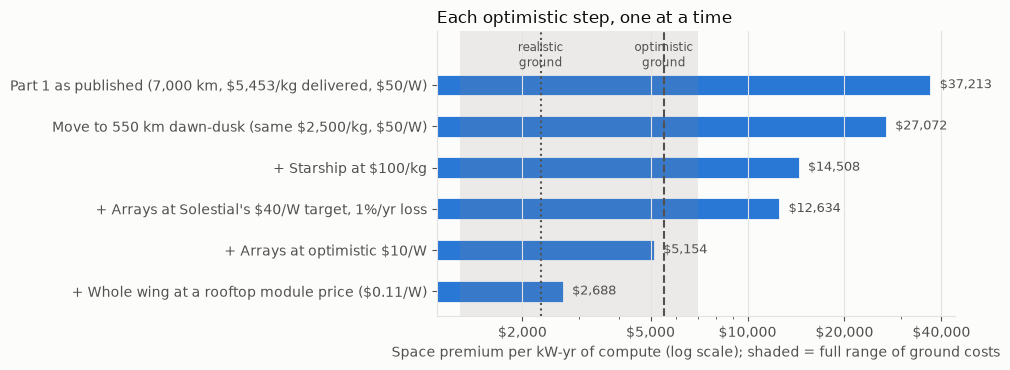

,Step,Premium $/kW-yr,vs optimistic ground,vs realistic ground
0,"Part 1 as published (7,000 km, $5,453/kg deliv...","37,213.41",6.77,16.32
1,"Move to 550 km dawn-dusk (same $2,500/kg, $50/W)","27,071.84",4.92,11.87
2,+ Starship at $100/kg,"14,508.11",2.64,6.36
3,"+ Arrays at Solestial's $40/W target, 1%/yr loss","12,633.96",2.30,5.54
4,+ Arrays at optimistic $10/W,"5,154.15",0.94,2.26
5,+ Whole wing at a rooftop module price ($0.11/W),"2,688.30",0.49,1.18


In [13]:
steps = [
    ("Part 1 as published (7,000 km, $5,453/kg delivered, $50/W)", None),
    ("Move to 550 km dawn-dusk (same $2,500/kg, $50/W)", dict(launch_cost_per_kg=2_500, array_cost_per_w=50, array_degr_per_yr=0)),
    ("+ Starship at $100/kg", dict(array_cost_per_w=50, array_degr_per_yr=0)),
    ("+ Arrays at Solestial's $40/W target, 1%/yr loss", dict(array_cost_per_w=40)),
    ("+ Arrays at optimistic $10/W", dict()),
    ("+ Whole wing at a rooftop module price ($0.11/W)", dict(array_cost_per_w=ROOFTOP_ARRAY_COST_PER_W)),
]
def staircase(steps) -> pd.DataFrame:
    """Premium per kW-yr for each (label, size_satellite arguments) step. None = Part 1 as published."""
    table = pd.DataFrame([(label, P1["premium_per_kw_yr"] if kw is None else size_satellite(**kw)["premium_per_kw_yr"])
                          for label, kw in steps], columns=["Step", "Premium $/kW-yr"])
    table["vs optimistic ground"] = table["Premium $/kW-yr"] / TERR
    table["vs realistic ground"] = table["Premium $/kW-yr"] / TERR_REAL
    return table

def plot_staircase(table: pd.DataFrame, title: str):

    fig, ax = plt.subplots(figsize=(10, 3.8))
    y = np.arange(len(table))[::-1]
    ax.barh(y, table["Premium $/kW-yr"], color=SERIES[0], height=0.55, edgecolor="#fcfcfb", linewidth=2)
    for yi, v in zip(y, table["Premium $/kW-yr"]):
        ax.annotate(f"${v:,.0f}", (v, yi), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK_2)
    ax.axvspan(TERR_LOW, TERR_HIGH, color=MUTED, alpha=0.15, lw=0)
    for xv, ls, txt in [(TERR, "--", "optimistic\nground"), (TERR_REAL, ":", "realistic\nground")]:
        ax.axvline(xv, color=INK_2, lw=1.5, ls=ls)
        ax.annotate(txt, (xv, y.max() + 0.35), fontsize=8.5, color=INK_2, ha="center", va="bottom")
    ax.set_ylim(-0.6, y.max() + 1.3)
    ax.set_xscale("log")
    ax.set_yticks(y, table["Step"])
    ax.xaxis.set_major_locator(mticker.FixedLocator([1_000, 2_000, 5_000, 10_000, 20_000, 40_000]))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    ax.set_xlabel("Space premium per kW-yr of compute (log scale); shaded = full range of ground costs")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()

stair = staircase(steps)
plot_staircase(stair, "Each optimistic step, one at a time")
display(stair)

**How to read the staircase:**
- Moving to 550 km and getting Starship-class launch takes out roughly two-thirds of the gap. **Launch was Part 1's biggest bill, and the orbit and Starship fix it.**
- After that, **the array price is the lever that's left**. At Solestial's \$40/W target, space still costs ~2× even the space-friendly yardstick, and ~5.5× the realistic one.
- At \$10/W, space just beats the space-friendly yardstick but still costs ~2.3× the realistic one.
- **Only with the whole wing at rooftop prices does space come within ~20% of the realistic ground yardstick.** Matching a normal datacenter takes array prices ~100× below today's cheapest flight panel (see 1.4).
- With the array nearly free, what remains is the radiators (\$2,000/m²) and the bus (\$0.5M per satellite). **Both are Part 1 placeholders**, and they now decide the answer. They need real sources (open item).

---
## 7. Launch price sweep across array technologies

How does the space premium change as Starship pricing falls, for each class of solar array? Each line is one array technology, from heritage satellite hardware to the rooftop-price bookend. The flat lines at the left show the array price setting a floor that cheaper launch can't break through.

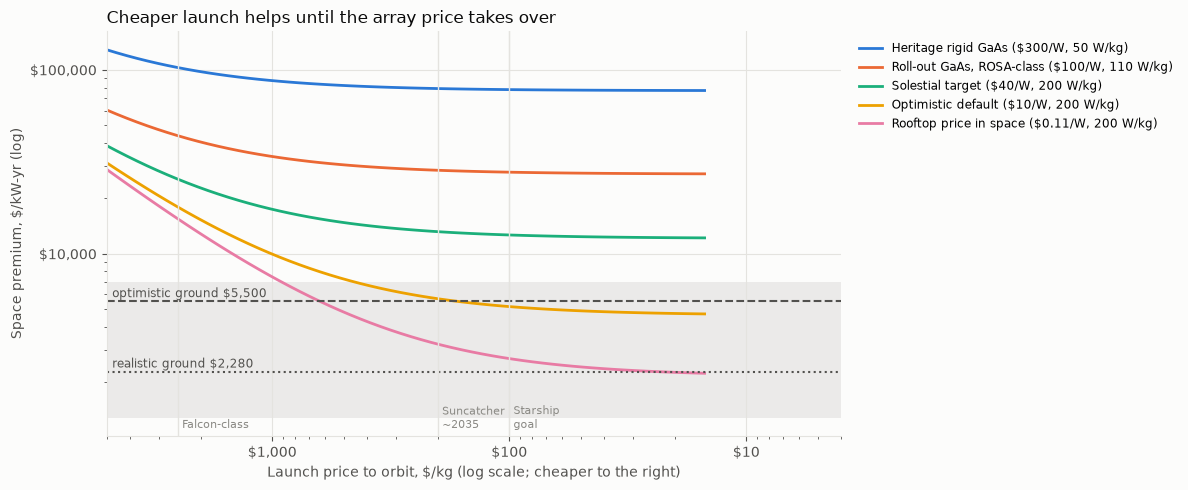

In [14]:
TIERS = [
    ("Heritage rigid GaAs ($300/W, 50 W/kg)", 300.0, 50.0),
    ("Roll-out GaAs, ROSA-class ($100/W, 110 W/kg)", 100.0, 110.0),
    ("Solestial target ($40/W, 200 W/kg)", 40.0, 200.0),
    ("Optimistic default ($10/W, 200 W/kg)", 10.0, 200.0),
    ("Rooftop price in space ($0.11/W, 200 W/kg)", ROOFTOP_ARRAY_COST_PER_W, 200.0),
]
launch_grid = np.logspace(np.log10(15), np.log10(5_000), 60)

fig, ax = plt.subplots(figsize=(12, 5))
for (name, cpw, wpk), color in zip(TIERS, SERIES):
    vals = [size_satellite(launch_cost_per_kg=L, array_cost_per_w=cpw, array_w_per_kg=wpk)["premium_per_kw_yr"]
            for L in launch_grid]
    ax.plot(launch_grid, vals, color=color, label=name)
ax.axhspan(TERR_LOW, TERR_HIGH, color=MUTED, alpha=0.15, lw=0)
for yv, ls, txt in [(TERR, "--", f"optimistic ground ${TERR:,.0f}"), (TERR_REAL, ":", f"realistic ground ${TERR_REAL:,.0f}")]:
    ax.axhline(yv, color=INK_2, lw=1.5, ls=ls)
    ax.annotate(txt, (5_000, yv), xytext=(4, 3), textcoords="offset points", ha="left", fontsize=8.5, color=INK_2)
for L, txt in [(2_500, "Falcon-class"), (200, "Suncatcher\n~2035"), (100, "Starship\ngoal")]:
    ax.axvline(L, color=GRID, lw=1)
    ax.annotate(txt, (L, 0.02), xycoords=ax.get_xaxis_transform(), xytext=(3, 0),
                textcoords="offset points", fontsize=8, color=MUTED)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(4, 5_000)
ax.invert_xaxis()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlabel("Launch price to orbit, $/kg (log scale; cheaper to the right)")
ax.set_ylabel("Space premium, $/kW-yr (log)")
ax.set_title("Cheaper launch helps until the array price takes over", loc="left")
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8.5)
plt.tight_layout(); plt.show()

---
## 8. What would have to be true: the break-even array price

For any launch price and array weight (W/kg), there is a **maximum array price (\$/W)** at which the space fleet exactly matches the ground yardstick. The premium is linear in array price, so this can be solved exactly:

```
break-even $/W = (ground yardstick × compute kW × life  −  everything except the array hardware)
                 ÷ array watts at beginning of life
```

A negative result means **even a free array wouldn't break even** at that launch price and weight.

In [15]:
def breakeven_array_cost_per_w(target_per_kw_yr=None, **kw) -> float:
    target = TERR if target_per_kw_yr is None else target_per_kw_yr
    s0 = size_satellite(array_cost_per_w=0.0, **kw)
    budget = target * s0["avg_compute_kw"] * s0["life_yr"]
    return (budget - s0["premium"]) / (s0["p_array_bol_kw"] * 1e3)

launch_pts = [2_500, 1_000, 500, 200, 100, 50, 20]
wpk_pts = [50, 110, 200, 300]
be = pd.DataFrame(
    {f"{w} W/kg": [breakeven_array_cost_per_w(launch_cost_per_kg=L, array_w_per_kg=w) for L in launch_pts] for w in wpk_pts},
    index=pd.Index([f"${L:,}/kg" for L in launch_pts], name="Launch price"),
)
print(f"Break-even array price, $/W (ground yardstick ${TERR:,.0f}/kW-yr; negative = no array price works)")
display(be)

# Sensitivity: the same table against the range of ground costs, at 200 W/kg
sens = pd.DataFrame({
    "Cheap ground": [breakeven_array_cost_per_w(TERR_LOW, launch_cost_per_kg=L) for L in launch_pts],
    "Realistic ground": [breakeven_array_cost_per_w(TERR_REAL, launch_cost_per_kg=L) for L in launch_pts],
    "Optimistic-for-space ground": [breakeven_array_cost_per_w(TERR, launch_cost_per_kg=L) for L in launch_pts],
    "Expensive ground": [breakeven_array_cost_per_w(TERR_HIGH, launch_cost_per_kg=L) for L in launch_pts],
}, index=be.index)
print(f"\nBreak-even $/W at 200 W/kg vs. ground cost (${TERR_LOW:,.0f} / ${TERR_REAL:,.0f} / ${TERR:,.0f} / ${TERR_HIGH:,.0f} per kW-yr)")
display(sens)

Break-even array price, $/W (ground yardstick $5,500/kW-yr; negative = no array price works)


,50 W/kg,110 W/kg,200 W/kg,300 W/kg
Launch price,,,,
"$2,500/kg",-89.79,-53.42,-39.79,-34.23
"$1,000/kg",-27.80,-13.26,-7.80,-5.58
$500/kg,-7.14,0.13,2.86,3.97
$200/kg,5.26,8.16,9.25,9.70
$100/kg,9.39,10.84,11.39,11.61
$50/kg,11.45,12.18,12.45,12.56
$20/kg,12.69,12.98,13.09,13.14



Break-even $/W at 200 W/kg vs. ground cost ($1,283 / $2,280 / $5,500 / $7,000 per kW-yr)


,Cheap ground,Realistic ground,Optimistic-for-space ground,Expensive ground
Launch price,,,,
"$2,500/kg",-56.70,-52.70,-39.79,-33.77
"$1,000/kg",-24.72,-20.72,-7.80,-1.79
$500/kg,-14.05,-10.06,2.86,8.87
$200/kg,-7.66,-3.66,9.25,15.27
$100/kg,-5.53,-1.53,11.39,17.40
$50/kg,-4.46,-0.46,12.45,18.47
$20/kg,-3.82,0.18,13.09,19.11


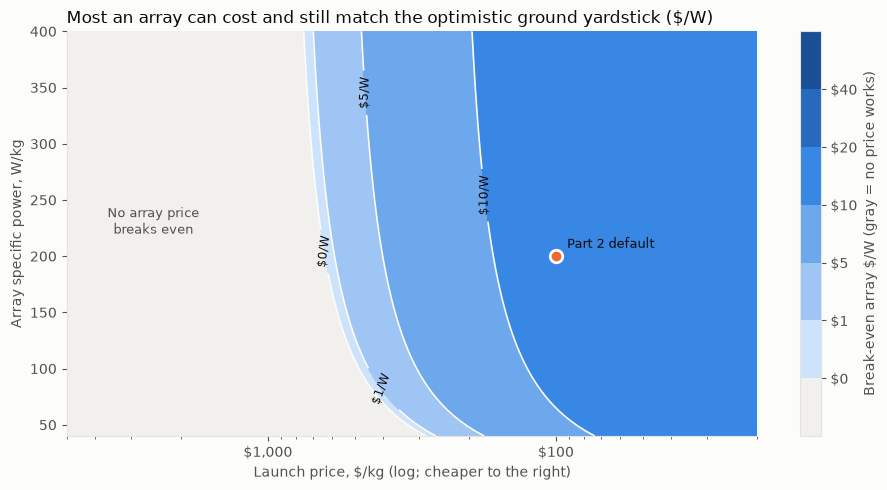

In [16]:
L_grid = np.logspace(np.log10(20), np.log10(5_000), 80)
W_grid = np.linspace(40, 400, 80)
Z = np.array([[breakeven_array_cost_per_w(launch_cost_per_kg=L, array_w_per_kg=w) for L in L_grid] for w in W_grid])

fig, ax = plt.subplots(figsize=(9.5, 5))
levels = [0, 1, 5, 10, 20, 40]
ramp = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95"]
cf = ax.contourf(L_grid, W_grid, Z, levels=[-1e9] + levels + [1e9], colors=["#f1f0ec"] + ramp, extend="neither")
cs = ax.contour(L_grid, W_grid, Z, levels=levels, colors="#fcfcfb", linewidths=1.2)
ax.clabel(cs, fmt=lambda v: f"${v:g}/W", fontsize=8.5, colors=INK)
ax.plot(LAUNCH_COST_PER_KG, ARRAY_SPECIFIC_POWER_W_PER_KG, "o", color=SERIES[1], ms=9, mec="#fcfcfb", mew=2)
ax.annotate("Part 2 default", (LAUNCH_COST_PER_KG, ARRAY_SPECIFIC_POWER_W_PER_KG), xytext=(8, 6),
            textcoords="offset points", fontsize=9, color=INK)
ax.set_xscale("log"); ax.invert_xaxis()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlabel("Launch price, $/kg (log; cheaper to the right)")
ax.set_ylabel("Array specific power, W/kg")
ax.set_title("Most an array can cost and still match the optimistic ground yardstick ($/W)", loc="left")
ax.text(2_500, 220, "No array price\nbreaks even", color=INK_2, fontsize=9, ha="center")
ax.grid(False)
cbar = fig.colorbar(cf, ax=ax, ticks=levels)
cbar.ax.set_yticklabels([f"${v}" for v in levels]); cbar.set_label("Break-even array $/W (gray = no price works)")
plt.tight_layout(); plt.show()

**How to read the break-even map:** each colored band is a ceiling on what the **whole deployed array** can cost per watt. Moving right (cheaper launch) or up (lighter arrays) raises the ceiling, but it levels off: once launch is nearly free, the ceiling is set by the ground yardstick minus radiators and bus.

Compare the ceiling at the Part 2 default point with the price ladder in Section 1.3. That comparison is the headline for the post:
- Against the **space-friendly** yardstick, at \$100/kg, the whole array can cost about **\$11/W**. That is roughly Starpath's \$11.20/W flight panel and well below Solestial's \$40/W target.
- Against the **realistic** yardstick, at \$100/kg, **no array price works**: the ceiling is slightly negative, so even a free array loses. Only near \$20/kg launch does the ceiling turn positive, and then at ~\$0.20/W. Radiators, the bus, and launch alone use up the whole realistic budget.
- **Everything hinges on which ground cost you believe, and on array prices falling ~100× or more.** These ceilings also assume Starship flies full by mass. Section 10.3 repeats them with real packing, which lowers them further.

---
## 9. Fitting into Starship

Starship sells *flights*, not kilograms. \$/kg only holds if every flight leaves full, so we check how many satellites fit by **mass**. Section 10 then checks fit by **volume**, using the stowed size from the SolidWorks model. Optimistic payload is 150 t to orbit.

Getting to a near-polar sun-synchronous orbit costs payload: a due-east launch borrows Earth's rotation, while a ~98° launch slightly fights it. The estimate below charges that extra speed to Starship's upper stage through the rocket equation. ⚠️ This is a rough estimate; no official Starship SSO figure has been published.

In [17]:
payload_sso_t = STARSHIP_PAYLOAD_LEO_T * SSO_FACTOR
sats_per_flight_leo = int(STARSHIP_PAYLOAD_LEO_T * 1_000 // BEST["m_total"])
sats_per_flight_sso = int(payload_sso_t * 1_000 // BEST["m_total"])
flight_price = LAUNCH_COST_PER_KG * STARSHIP_PAYLOAD_LEO_T * 1_000

print(f"Extra Δv to reach {INC_DEG:.1f}° from {LAUNCH_SITE_LAT_DEG:.0f}°N: ~{SSO_EXTRA_DV:,.0f} m/s  [EST]")
print(f"Starship payload: {STARSHIP_PAYLOAD_LEO_T:.0f} t due-east  ->  ~{payload_sso_t:.0f} t to SSO ({SSO_FACTOR:.0%})")
print(f"Implied flight price at ${LAUNCH_COST_PER_KG:,.0f}/kg x {STARSHIP_PAYLOAD_LEO_T:.0f} t: ${flight_price/1e6:,.0f}M")
print(f"Satellites per flight (mass-limited): {sats_per_flight_leo} if due-east capacity, {sats_per_flight_sso} to SSO")
print(f"Flights for {n_sats:,} satellites: {math.ceil(n_sats/sats_per_flight_sso):,} (SSO)")
s_pen = size_satellite(apply_sso_penalty=True)
print(f"Premium with the SSO payload penalty applied: ${s_pen['premium_per_kw_yr']:,.0f}/kW-yr "
      f"(vs ${BEST['premium_per_kw_yr']:,.0f} without)")
print(f"Each satellite must also stow a {BEST['a_array_m2']:.0f} m² array and {BEST['a_rad_panel_m2']:.0f} m² of radiator panels: "
      f"Section 10 checks the fit by volume.")

Extra Δv to reach 97.6° from 26°N: ~479 m/s  [EST]
Starship payload: 150 t due-east  ->  ~113 t to SSO (75%)
Implied flight price at $100/kg x 150 t: $15M
Satellites per flight (mass-limited): 50 if due-east capacity, 38 to SSO
Flights for 1,797 satellites: 48 (SSO)
Premium with the SSO payload penalty applied: $5,330/kW-yr (vs $5,154 without)
Each satellite must also stow a 347 m² array and 171 m² of radiator panels: Section 10 checks the fit by volume.


---
## 10. The SolidWorks reference satellite and how it packs into Starship

So far the bus has been a flat 25% of satellite mass, and Starship packing has been checked by mass only. A SolidWorks model replaces both with geometry:

1. **This notebook** sizes the primary structure for launch loads, lists bus equipment masses, and writes `cad/params.json`.
2. **`cad/build_satellite.py`** (run with SolidWorks open) builds each packaging concept under `cad/<concept>/`, then writes `mass_props.json` and renders to `images/`. The SolidWorks files are not in the repo; run the script to regenerate them. Each concept has three assemblies:
   - `satellite_deployed.SLDASM`: on-orbit configuration (the same for both concepts),
   - `satellite_stowed.SLDASM`: folded for launch,
   - `starship_stack.SLDASM`: as many stowed satellites as fit in Starship's payload bay, including its tapered nose.
3. **This section** reads the results back: bottom-up bus mass, satellites per flight by volume, and inertia for attitude control.

Model axes: **+X** = direction of travel, **+Y** = zenith (and the Starship axis when stowed), **+Z** = toward the Sun.

```
.venv\Scripts\python.exe cad\build_satellite.py      # SolidWorks must be open
```

**Two packaging concepts, same satellite in orbit:**

| | Tower (first pass) | Flat-pack (packing-optimized) |
|---|---|---|
| Stowed shape | 4 × 4.4 × 2.2 m box standing on end | 5.7 × 5.0 m plate, 0.56 m thick |
| Compute module | 1.2 × 2.4 × 1.0 m block (2.9 m³) | Trays laid flat: 2.4 × 0.26 × 2.54 m (1.58 m³, the volume of a ground NVL72 rack) |
| Solar wings | Rolled (ROSA-style) | Z-folded flat (same stowed power density, 40 kW/m³) |
| Radiators | 4 m panels stacked against the sides | Eight plate-sized panels stacked on top |
| Launch loads | 4 tall longerons (sized against buckling) | 4 short corner posts (sized by compression), like a Starlink stack |

Masses of items not modeled in detail (compute module, solar wings, radiator panels, equipment boxes) are set by giving each part a uniform density that produces its target mass, so inertia stays physical. The **primary structure is drawn as real CFRP tubes**, and its mass comes from SolidWorks geometry.

In [18]:
import json, os, sys
sys.path.insert(0, "cad")
from packing import sats_per_flight as pack_sats

equipment = {
    "power_conditioning": BEST["p_array_bol_kw"] / PCDU_KW_PER_KG,
    "electric_propulsion": EP_SYSTEM_KG,
    "propellant_tank": PROP_TANK_KG,
    "reaction_wheels": REACTION_WHEELS_KG,
    "laser_terminals": LASER_TERMINALS_KG,
    "avionics": AVIONICS_KG,
    "array_drives": ARRAY_DRIVES_KG,
    "stack_interfaces": STACK_INTERFACE_KG,
}
wing_stowed_volume_each = BEST["p_array_bol_kw"] / 2 / ARRAY_STOWED_KW_PER_M3

# Starship's payload envelope with the extended option: the extra height goes into the full-width section.
BAY_PROFILE = [(h + (STARSHIP_BAY_EXTENSION_M if h >= 8 else 0), r) for h, r in STARSHIP_BAY_PROFILE_M]
BAY_TOP_M = BAY_PROFILE[-1][0]
bay = {"profile": [list(point) for point in BAY_PROFILE]}

# ---- Concept 1, "tower": bus stands along the Starship axis; 4 CFRP longerons sized against buckling ----
layers_tower = int(BAY_TOP_M // BUS_HEIGHT_M)             # sized as if every layer were full (conservative)
p_longeron = BEST["m_total"] * layers_tower * LAUNCH_AXIAL_G * G0 / 4 * STRUCTURE_FACTOR_OF_SAFETY
i_req = p_longeron * BUS_HEIGHT_M**2 / (math.pi**2 * CFRP_MODULUS_PA)
tube_outer = max(LONGERON_MIN_OUTER_M, (1.5 * i_req / LONGERON_WALL_M) ** (1 / 3))  # thin square tube: I ≈ (2/3)·b³·t
frame_size = (COMPUTE_MODULE_DIMS_M[0] + 2 * FRAME_CLEARANCE_M, BUS_HEIGHT_M, COMPUTE_MODULE_DIMS_M[2] + 2 * FRAME_CLEARANCE_M)
tower = {
    "compute": {"size": list(COMPUTE_MODULE_DIMS_M), "mass": M_COMPUTE_KG},
    "frame": {"size": list(frame_size), "tube_outer": tube_outer, "tube_wall": LONGERON_WALL_M, "density": CFRP_DENSITY_KG_M3},
    "wing": {"area_each": BEST["a_array_m2"] / 2, "width": ARRAY_WING_WIDTH_M, "mass_each": BEST["m_array"] / 2,
             "stowed_volume_each": wing_stowed_volume_each},
    "radiator": {"panel_area_total": BEST["a_rad_panel_m2"], "fin_width": RADIATOR_FIN_WIDTH_M,
                 "panel_max_length": RADIATOR_PANEL_MAX_LENGTH_M, "thickness": RADIATOR_PANEL_THICKNESS_M,
                 "mass_total": BEST["m_rad"]},
    "equipment": equipment, "propellant": BEST["m_prop"], "bay": bay,
}

# ---- Concept 2, "flatpack": Starlink-style plates stacked along the bay axis ----
def flatpack_geometry(footprint=FLATPACK_FOOTPRINT_M, compute_dims=COMPUTE_FLAT_DIMS_M, inside_frame=True,
                      profile=BAY_PROFILE) -> dict:
    """Stowed layout of one flat-pack satellite (one layer of the stack), and how many fit in the bay.
    inside_frame=True: contents sit within the depth of the deck frame. False: on top of it (first version)."""
    Lx, Lz = footprint
    cx, cy, cz = compute_dims
    g = FLATPACK_GAP_M
    # Each folded wing sits between the compute module and the end of the deck.
    wing_x = (Lx - cx) / 2 - 2 * g - (2 * DECK_TUBE_M if inside_frame else POST_OUTER_M)
    wing_z = Lz - 2 * POST_OUTER_M - 2 * g                    # = deployed wing width; radiator panels are as wide
    wing_t = wing_stowed_volume_each / (wing_x * wing_z)       # folded thickness
    panel_l_max = Lx - 2 * POST_OUTER_M - 2 * g                # radiator panels fit between the corner posts
    n_pan = math.ceil(BEST["a_rad_panel_m2"] / (panel_l_max * wing_z))
    n_pan += n_pan % 2                                         # even: half the panels on each fin
    eq_h = max(cy, wing_t)                                     # equipment layer: compute trays and folded wings side by side
    layer_h = (0 if inside_frame else DECK_TUBE_M) + eq_h + g + n_pan * RADIATOR_STACK_PITCH_M + g
    per_flight = pack_sats((Lx + 0.02, layer_h, Lz + 0.02), profile)["total"]   # +2 cm: post caps overhang the plate
    return dict(Lx=Lx, Lz=Lz, wing_x=wing_x, wing_z=wing_z, wing_t=wing_t, n_pan=n_pan, eq_h=eq_h, layer_h=layer_h,
                panel_l=BEST["a_rad_panel_m2"] / (n_pan * wing_z), per_flight=per_flight)

FP = flatpack_geometry()
g = FLATPACK_GAP_M
p_post = BEST["m_total"] * FP["per_flight"] * LAUNCH_AXIAL_G * G0 / 4 * STRUCTURE_FACTOR_OF_SAFETY
post_wall = min(p_post / CFRP_COMPRESSIVE_ALLOW_PA / (4 * POST_OUTER_M), POST_OUTER_M / 2 - 0.005)
flatpack = {
    "compute": {"size": list(COMPUTE_FLAT_DIMS_M), "mass": M_COMPUTE_KG},
    "deck": {"footprint": [FP["Lx"], FP["Lz"]], "height": FP["layer_h"], "tube": DECK_TUBE_M, "wall": LONGERON_WALL_M,
             "post_outer": POST_OUTER_M, "post_wall": post_wall, "density": CFRP_DENSITY_KG_M3, "gap": g,
             "eq_h": FP["eq_h"], "rad_y0": FP["eq_h"] + g},
    "wing": {"area_each": BEST["a_array_m2"] / 2, "width": FP["wing_z"], "mass_each": BEST["m_array"] / 2,
             "pack": [FP["wing_x"], FP["wing_t"], FP["wing_z"]]},
    "radiator": {"n_panels": FP["n_pan"], "panel_length": FP["panel_l"], "panel_width": FP["wing_z"],
                 "thickness": RADIATOR_PANEL_THICKNESS_M, "pitch": RADIATOR_STACK_PITCH_M, "mass_total": BEST["m_rad"]},
    "equipment": equipment, "propellant": BEST["m_prop"], "bay": bay,
}

cad_params = {"tower": tower, "flatpack": flatpack}
os.makedirs("cad", exist_ok=True)
with open("cad/params.json", "w") as f:
    json.dump(cad_params, f, indent=2)

print(f"Tower:     {layers_tower}-high stack -> longeron load {p_longeron/1e3:,.0f} kN -> "
      f"{tube_outer*1e3:.0f} mm × {LONGERON_WALL_M*1e3:.0f} mm CFRP tubes (buckling)")
print(f"Flat-pack: {FP['Lx']:.1f} × {FP['Lz']:.1f} m plate, layer {FP['layer_h']:.2f} m = equipment/compute {FP['eq_h']:.2f} + "
      f"{FP['n_pan']} radiator panels {FP['n_pan']*RADIATOR_STACK_PITCH_M:.2f} + gaps;  folded wings {FP['wing_t']*100:.0f} cm thick")
print(f"           {FP['per_flight']}-high stack -> post load {p_post/1e3:,.0f} kN -> {POST_OUTER_M*1e3:.0f} mm posts, "
      f"{post_wall*1e3:.1f} mm wall (compression)")
print(f"           radiator panels {FP['panel_l']:.2f} × {FP['wing_z']:.2f} m (deployed fins {FP['n_pan']//2} panels each)")
print(f"Bus equipment: {sum(equipment.values()):,.0f} kg  ->  wrote cad/params.json")
display(pd.Series(equipment, name="kg").round(1).to_frame())


Tower:     5-high stack -> longeron load 327 kN -> 161 mm × 3 mm CFRP tubes (buckling)
Flat-pack: 5.7 × 5.0 m plate, layer 0.56 m = equipment/compute 0.26 + 8 radiator panels 0.24 + gaps;  folded wings 26 cm thick
           25-high stack -> post load 1,633 kN -> 120 mm posts, 11.3 mm wall (compression)
           radiator panels 4.56 × 4.70 m (deployed fins 4 panels each)
Bus equipment: 311 kg  ->  wrote cad/params.json


,kg
power_conditioning,92.50
electric_propulsion,40.00
propellant_tank,15.00
reaction_wheels,48.00
laser_terminals,45.00
avionics,30.00
array_drives,20.00
stack_interfaces,20.00


### 10.1 Fitting Starship's real payload bay

Starship's payload bay is not a simple cylinder. The Starship Users Guide shows the full 8 m width only for the lower part, then a taper toward the nose. With the extended 22 m option (taken optimistically as all extra full-width height), about **30% of the volume is in the taper**, where a wide plate does not fit.

That cost the first flat-pack design 40% of its satellites. Three changes win some of it back:

1. **Sit everything inside the deck frame**, not on top of it. The frame tubes then cost a little floor area and no height.
2. **Shrink the plate's diagonal** so a few more layers reach up into the taper.
3. **Make the compute tray thinner and wider** (same volume), to match the folded wings beside it.


In [19]:
CYLINDER_8x22 = [(0, 4.0), (22.0, 4.0)]      # what the first version of this section assumed
fit_steps = [
    ("First flat-pack, in an idealized 8 m × 22 m cylinder", dict(footprint=(6.4, 4.6), compute_dims=(2.4, 0.30, 2.2), inside_frame=False, profile=CYLINDER_8x22)),
    ("Same satellite, in Starship's real envelope",          dict(footprint=(6.4, 4.6), compute_dims=(2.4, 0.30, 2.2), inside_frame=False)),
    ("+ Contents inside the deck frame",                      dict(footprint=(6.4, 4.6), compute_dims=(2.4, 0.30, 2.2))),
    ("+ Plate resized to reach into the taper",               dict(footprint=(6.0, 4.6), compute_dims=(2.4, 0.30, 2.2))),
    ("+ Thinner, wider compute tray (chosen design)",         dict()),
]
rows = []
for label, kw in fit_steps:
    s = flatpack_geometry(**kw)
    rows.append({"Step": label, "Plate [m]": f"{s['Lx']:.1f} × {s['Lz']:.1f}", "Layer height [m]": s["layer_h"],
                 "Satellites per flight": s["per_flight"]})
display(pd.DataFrame(rows).set_index("Step"))

# Is there a better plate? Search plate sizes and tray thicknesses (tray volume fixed).
tray_volume = math.prod(COMPUTE_FLAT_DIMS_M)
best = (0, None)
for tray_t in (0.30, 0.28, 0.26, 0.24, 0.22, 0.20):
    tray = (COMPUTE_FLAT_DIMS_M[0], tray_t, tray_volume / (COMPUTE_FLAT_DIMS_M[0] * tray_t))
    for Lx in np.arange(4.6, 7.01, 0.1):
        for Lz in np.arange(4.0, 5.81, 0.1):
            strip = Lz / 2 - DECK_TUBE_M - FLATPACK_GAP_M - tray[2] / 2      # room beside the tray for bus equipment
            if strip < 0.9 * 0.30 / tray_t or (Lx - tray[0]) / 2 < 0.6:      # equipment keeps its volume as it gets flatter
                continue
            n = flatpack_geometry((Lx, Lz), tray)["per_flight"]
            if n > best[0]:
                best = (n, (round(float(Lx), 1), round(float(Lz), 1), tray_t))
print(f"Best found by the search: {best[0]} per flight (first hit: {best[1][0]} × {best[1][1]} m plate, {best[1][2]*100:.0f} cm tray). "
      f"Chosen design: {FP['per_flight']} per flight.")

# Why it stops there: a volume budget
full_width_h = BAY_PROFILE[1][0]
v_full = math.pi * BAY_PROFILE[0][1]**2 * full_width_h
v_taper = sum(math.pi * (h1 - h0) * (r0**2 + r0 * r1 + r1**2) / 3 for (h0, r0), (h1, r1) in zip(BAY_PROFILE[1:], BAY_PROFILE[2:]))
v_contents = (math.prod(COMPUTE_FLAT_DIMS_M) + 2 * wing_stowed_volume_each
              + BEST["a_rad_panel_m2"] * RADIATOR_STACK_PITCH_M + sum(equipment.values()) / 300)   # equipment at ~300 kg/m³ [EST]
v_used = FP["per_flight"] * FP["Lx"] * FP["Lz"] * FP["layer_h"]
print(f"Bay volume: {v_full + v_taper:,.0f} m³ = {v_full:,.0f} full-width + {v_taper:,.0f} in the taper ({v_taper/(v_full+v_taper):.0%}).")
print(f"One satellite's stowed contents: ~{v_contents:.1f} m³. {FP['per_flight']} satellites = {FP['per_flight']*v_contents:,.0f} m³ of contents "
      f"in {v_used:,.0f} m³ of plates: the plates are {FP['per_flight']*v_contents/v_used:.0%} full, and fill {v_used/(v_full+v_taper):.0%} of the bay.")


,Plate [m],Layer height [m],Satellites per flight
Step,,,
"First flat-pack, in an idealized 8 m × 22 m cylinder",6.4 × 4.6,0.68,32
"Same satellite, in Starship's real envelope",6.4 × 4.6,0.68,19
+ Contents inside the deck frame,6.4 × 4.6,0.60,21
+ Plate resized to reach into the taper,6.0 × 4.6,0.60,23
"+ Thinner, wider compute tray (chosen design)",5.7 × 5.0,0.56,25


Best found by the search: 25 per flight (first hit: 5.4 × 4.6 m plate, 30 cm tray). Chosen design: 25 per flight.
Bay volume: 924 m³ = 641 full-width + 282 in the taper (31%).
One satellite's stowed contents: ~11.2 m³. 25 satellites = 281 m³ of contents in 399 m³ of plates: the plates are 70% full, and fill 43% of the bay.


**Reading the fit:**
- **The real bay costs 40% of the idealized count** (32 → 19). The plate is nearly as wide as the bay, so it only fits in the full-width section, and the taper above it stays empty.
- **Three layout changes win almost half of that back** (19 → 25), with no new technology: only where things sit and the shape of the compute tray.
- **The search finds nothing better than 25.** The reason is the volume budget: the stowed plates are already about 70% full, and identical wide plates can't use most of the taper. A narrower plate would reach higher, but each layer would get thicker, and the count comes out the same or worse.
- Going beyond 25 needs the contents themselves to get thinner (Section 10.2).


In [20]:
payload_t = STARSHIP_PAYLOAD_LEO_T * (SSO_FACTOR if APPLY_SSO_PAYLOAD_PENALTY else 1.0)
m_core = BEST["m_compute"] + BEST["m_array"] + BEST["m_rad"]
CAD_RUNS, rows = {}, []
for concept in ["tower", "flatpack"]:
    path = f"cad/{concept}/mass_props.json"
    if not os.path.exists(path):
        print(f"{path} not found: run cad/build_satellite.py with SolidWorks open, then rerun this cell.")
        continue
    with open(path) as f:
        run = json.load(f)
    if run["params"] != json.loads(json.dumps(cad_params[concept])):
        print(f"⚠️ {path} was built from different parameters; rebuild the CAD model.")
    m_structure = run["part_masses"][run["structure_part"]]
    m_dry = (m_core + m_structure + sum(equipment.values())) / (1 - UNMODELED_MASS_FRAC)
    bus = m_dry - m_core
    stow = run["stowed"]["size"]
    pack = pack_sats(stow, BAY_PROFILE)
    n_mass = int(payload_t * 1_000 // size_satellite(bus_mass_kg=bus)["m_total"])
    n_flight = min(n_mass, pack["total"])
    sat = size_satellite(bus_mass_kg=bus, sats_per_flight=n_flight)
    n_sats_c = math.ceil(TARGET_AVG_COMPUTE_MW * 1_000 / sat["avg_compute_kw"])
    CAD_RUNS[concept] = dict(run=run, bus=bus, n_flight=n_flight, sat=sat)
    rows.append({
        "Concept": concept,
        "Stowed envelope (X × Y × Z) [m]": " × ".join(f"{v:.2f}" for v in stow),
        "Stowed box volume [m³]": stow[0] * stow[1] * stow[2],
        "Primary structure [kg] (CAD)": m_structure,
        "Bottom-up bus [kg]": bus,
        "Satellite mass [kg]": sat["m_total"],
        "Layers × most per layer": f"{pack['layers']} × {max(pack['per_layer'])}",
        "Satellites/flight by volume": pack["total"],
        "Satellites/flight by mass": n_mass,
        "Satellites/flight": n_flight,
        "Limited by": "volume" if pack["total"] < n_mass else "mass",
        "Effective launch $/kg": sat["eff_cost_per_kg"],
        "Premium $/kW-yr": sat["premium_per_kw_yr"],
        "vs realistic ground": sat["premium_per_kw_yr"] / TERR_REAL,
        "Starship flights for 200 MW": math.ceil(n_sats_c / n_flight),
    })
rows.insert(0, {"Concept": "no packing limit (Section 9)", "Satellite mass [kg]": BEST["m_total"],
                "Satellites/flight by mass": int(payload_t * 1_000 // BEST["m_total"]),
                "Effective launch $/kg": BEST["eff_cost_per_kg"], "Premium $/kW-yr": BEST["premium_per_kw_yr"],
                "vs realistic ground": BEST["premium_per_kw_yr"] / TERR_REAL})
packing_table = pd.DataFrame(rows).set_index("Concept").T
display(packing_table)

CAD = CAD_RUNS.get(STOWED_CONCEPT, {}).get("run")
if CAD is not None:
    CAD_SAT, N_PER_FLIGHT = CAD_RUNS[STOWED_CONCEPT]["sat"], CAD_RUNS[STOWED_CONCEPT]["n_flight"]
    dep = CAD["deployed"]
    I_travel, I_zenith, I_normal = dep["Ixx"], dep["Iyy"], dep["Izz"]
    n2 = MU_EARTH / (R_EARTH + 1_000 * ALT_KM) ** 3          # orbital rate squared
    # Gravity pulls slightly harder on the lower end of a long object, which tries to stand it
    # upright. Tilting the satellite by an angle θ in the orbit plane gives a torque of
    # 1.5·n²·(I_zenith − I_travel)·sin 2θ. Positive stiffness means the torque pushes it further over.
    stiffness = 3 * n2 * (I_zenith - I_travel)               # N·m per radian, for small tilts
    torque_1deg = stiffness * math.radians(1.0)
    h_per_orbit = torque_1deg * orbital_period_s(ALT_KM)     # a steady tilt gives a steady torque, which adds up
    h_wheels = 4 * REACTION_WHEEL_MOMENTUM_NMS
    print(f"Chosen concept: {STOWED_CONCEPT}")
    print(f"Deployed inertia about the center of mass: {I_travel:,.0f} (travel axis), {I_zenith:,.0f} (zenith axis), "
          f"{I_normal:,.0f} (orbit normal) kg·m²")
    if stiffness > 0:
        print(f"The long axis lies along the direction of travel, so gravity tries to tip the satellite upright "
              f"(uncontrolled, a small tilt grows ~2.7× every {math.sqrt(I_normal / stiffness) / 60:.0f} min).")
    else:
        print("The long axis points at Earth, so gravity holds the satellite in this attitude.")
    print(f"Holding a steady 1° tilt takes {abs(torque_1deg)*1e3:,.1f} mN·m, which builds up {abs(h_per_orbit):,.0f} N·m·s per orbit. "
          f"The four wheels store ~{h_wheels:.0f} N·m·s in total: full in {h_wheels/abs(h_per_orbit):.1f} orbits.")


Concept,no packing limit (Section 9),tower,flatpack
Satellite mass [kg],"2,959.66","2,867.84","2,825.53"
Satellites/flight by mass,50,52,53
Effective launch $/kg,100.00,475.49,212.35
Premium $/kW-yr,"5,154.15","7,071.97","5,700.27"
vs realistic ground,2.26,3.10,2.50
Stowed envelope (X × Y × Z) [m],NaN,4.00 × 4.36 × 2.21,5.72 × 0.56 × 5.02
Stowed box volume [m³],NaN,38.57,16.08
Primary structure [kg] (CAD),NaN,101.62,62.70
Bottom-up bus [kg],NaN,638.53,596.22
Layers × most per layer,NaN,4 × 3,25 × 1


Chosen concept: flatpack
Deployed inertia about the center of mass: 91,455 (travel axis), 350,990 (zenith axis), 435,998 (orbit normal) kg·m²
The long axis lies along the direction of travel, so gravity tries to tip the satellite upright (uncontrolled, a small tilt grows ~2.7× every 11 min).
Holding a steady 1° tilt takes 16.3 mN·m, which builds up 94 N·m·s per orbit. The four wheels store ~200 N·m·s in total: full in 2.1 orbits.


**Reading the CAD results:**
- **The bottom-up bus lands a little below Part 1's flat 25%** (596–639 kg against ~730 kg), so that rule of thumb holds up.
- **Packing is the bigger story.** The deployed satellite is huge but mostly thin film, so Starship runs out of *room* before it runs out of *lift*. You still pay for the whole flight, so the true launch price per kg rises.
- **The first-pass "tower" fits only 11 satellites per flight**, against ~52 by mass. That turns \$100/kg into an effective ~\$480/kg.
- **Re-packaging as a Starlink-style flat-pack** (wide thin plates stacked along the bay) fits **25 per flight**, cutting the effective price to ~\$210/kg and the number of Starship flights for 200 MW by more than half. That is still less than half of what Starship could lift. Its structure is lighter too: short corner posts in compression instead of tall longerons sized against buckling.

| Concept | Stowed | Deployed | In Starship |
|---|---|---|---|
| Tower | ![](cad/tower/images/satellite_stowed.jpg) | ![](cad/tower/images/satellite_deployed.jpg) | ![](cad/tower/images/starship_stack.jpg) |
| Flat-pack | ![](cad/flatpack/images/satellite_stowed.jpg) | ![](cad/flatpack/images/satellite_deployed.jpg) | ![](cad/flatpack/images/starship_stack.jpg) |

### 10.2 What would it take to fill Starship by mass?

The flat-pack stack is set by **layer height**: one satellite per layer, so satellites per flight ≈ usable bay height ÷ layer height. Each layer holds the compute trays and folded wings side by side, with the stack of folded radiator panels on top. Below, each of the three is made thinner in turn, to see what would let a full Starship carry as many satellites as it can lift.


In [21]:
m_sat_fp = CAD_RUNS["flatpack"]["sat"]["m_total"] if "flatpack" in CAD_RUNS else BEST["m_total"]
n_by_mass = int(payload_t * 1_000 // m_sat_fp)

def per_flight(compute_thick, panel_thick, wing_kw_per_m3=ARRAY_STOWED_KW_PER_M3):
    """Satellites per flight for the chosen plate, if its contents were thinner."""
    wing_t = FP["wing_t"] * ARRAY_STOWED_KW_PER_M3 / wing_kw_per_m3      # folded-wing thickness scales with stowed density
    panel_gap = RADIATOR_STACK_PITCH_M - RADIATOR_PANEL_THICKNESS_M
    layer = max(compute_thick, wing_t) + g + FP["n_pan"] * (panel_thick + panel_gap) + g
    by_volume = pack_sats((FP["Lx"] + 0.02, layer, FP["Lz"] + 0.02), BAY_PROFILE)["total"]
    return min(n_by_mass, by_volume)

compute_opts = [0.26, 0.22, 0.18, 0.15]
panel_opts = [0.025, 0.020, 0.015, 0.010]
sweep = pd.DataFrame(
    [[per_flight(c, p) for p in panel_opts] for c in compute_opts],
    index=pd.Index([f"{c*100:.0f} cm" for c in compute_opts], name="Compute-tray layer"),
    columns=pd.Index([f"{p*1000:.0f} mm" for p in panel_opts], name="Radiator panel thickness"),
)
print(f"Satellites per flight, wings folded at {ARRAY_STOWED_KW_PER_M3:.0f} kW/m³ (capped at {n_by_mass} by mass).")
display(sweep)

wing_opts = [40, 60, 80, 100]
sweep_w = pd.DataFrame(
    [[per_flight(c, 0.010, w) for w in wing_opts] for c in compute_opts],
    index=pd.Index([f"{c*100:.0f} cm" for c in compute_opts], name="Compute-tray layer"),
    columns=pd.Index([f"{w} kW/m³" for w in wing_opts], name="Folded-wing stowed density"),
)
print(f"Same, with 10 mm radiator panels, varying how densely the solar wings fold "
      f"(folded wing is {FP['wing_t']*100:.0f} cm thick at {ARRAY_STOWED_KW_PER_M3:.0f} kW/m³):")
display(sweep_w)

# How much does packing matter? It depends on the launch price.
launch_opts = [100, 200, 500, 1_000]
rows = []
for name, bus, n in [("Mass-limited (no packing limit)", None, None)] + \
        [(f"{c} ({CAD_RUNS[c]['n_flight']}/flight)", CAD_RUNS[c]["bus"], CAD_RUNS[c]["n_flight"]) for c in CAD_RUNS]:
    rows.append({"Packaging": name, **{f"${L:,}/kg": size_satellite(launch_cost_per_kg=L, bus_mass_kg=bus, sats_per_flight=n)["premium_per_kw_yr"]
                                       for L in launch_opts}})
packing_vs_launch = pd.DataFrame(rows).set_index("Packaging")
print("Space premium, $/kW-yr, by packaging and launch price ($/kg = price of a full 150 t flight ÷ 150 t):")
display(packing_vs_launch.round(0))


Satellites per flight, wings folded at 40 kW/m³ (capped at 53 by mass).


Radiator panel thickness,25 mm,20 mm,15 mm,10 mm
Compute-tray layer,,,,
26 cm,25,26,29,31
22 cm,25,27,29,32
18 cm,25,27,29,32
15 cm,25,27,29,32


Same, with 10 mm radiator panels, varying how densely the solar wings fold (folded wing is 26 cm thick at 40 kW/m³):


Folded-wing stowed density,40 kW/m³,60 kW/m³,80 kW/m³,100 kW/m³
Compute-tray layer,,,,
26 cm,31,31,31,31
22 cm,32,35,35,35
18 cm,32,38,38,38
15 cm,32,39,42,42


Space premium, $/kW-yr, by packaging and launch price ($/kg = price of a full 150 t flight ÷ 150 t):


,$100/kg,$200/kg,$500/kg,"$1,000/kg"
Packaging,,,,
Mass-limited (no packing limit),"5,154.00","5,686.00","7,281.00","9,939.00"
tower (11/flight),"7,072.00","9,521.00","16,870.00","29,117.00"
flatpack (25/flight),"5,700.00","6,778.00","10,011.00","15,400.00"


**Reading the packing sweep:**
- **Each fix exposes the next bottleneck.** Thinner compute trays alone do nothing: the **folded solar wings** beside them (~26 cm at ROSA-class stowed density) already set the layer height. Thinner radiator panels help a little (25 → 31).
- **Even all three together fall short.** Compute trays 15 cm thick, radiator panels 10 mm thick, and solar wings folding 2.5× as densely as today's roll-out arrays reach ~42 satellites per flight, against ~53 by mass. **This satellite fills Starship's volume long before its lift.**
- **How much packing matters depends on the launch price.** At \$100/kg, flying 25 instead of ~53 per flight adds ~10% to the premium: launch is a small slice of it. At \$500–1,000/kg, poor packing multiplies the single biggest cost. **Packaging is a first-order design driver unless launch is nearly free**, and \$/kg alone understates the true launch cost of a large, flimsy satellite.


### 10.3 The headline numbers, with the real bus and real packing

Sections 5–8 assumed a flat 25% bus and a Starship that always flies full by mass. Here the staircase and the break-even array price are repeated with the SolidWorks bus mass and the number of satellites that actually fit in a flight. **These are the numbers to quote.**


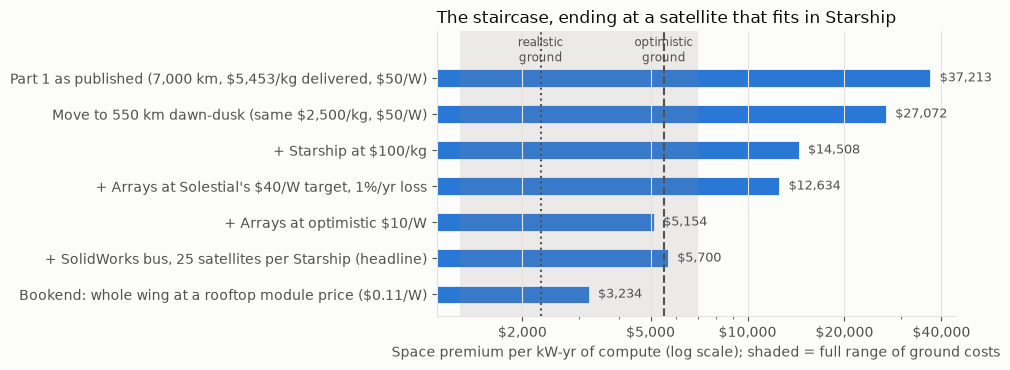

,Step,Premium $/kW-yr,vs optimistic ground,vs realistic ground
0,"Part 1 as published (7,000 km, $5,453/kg deliv...","37,213.41",6.77,16.32
1,"Move to 550 km dawn-dusk (same $2,500/kg, $50/W)","27,071.84",4.92,11.87
2,+ Starship at $100/kg,"14,508.11",2.64,6.36
3,"+ Arrays at Solestial's $40/W target, 1%/yr loss","12,633.96",2.30,5.54
4,+ Arrays at optimistic $10/W,"5,154.15",0.94,2.26
5,"+ SolidWorks bus, 25 satellites per Starship (...","5,700.27",1.04,2.50
6,Bookend: whole wing at a rooftop module price ...,"3,234.43",0.59,1.42


Break-even array price, $/W, at 200 W/kg (negative = no array price works). 'As packed' = SolidWorks bus, 25 satellites per flight.


,"Realistic ground, full by mass","Realistic ground, as packed","Optimistic ground, full by mass","Optimistic ground, as packed"
Launch price,,,,
"$2,500/kg",-52.70,-107.46,-39.79,-94.55
"$1,000/kg",-20.72,-42.62,-7.80,-29.71
$500/kg,-10.06,-21.01,2.86,-8.09
$200/kg,-3.66,-8.04,9.25,4.87
$100/kg,-1.53,-3.72,11.39,9.20
$50/kg,-0.46,-1.56,12.45,11.36
$20/kg,0.18,-0.26,13.09,12.65


In [22]:
if CAD is None:
    print("No CAD results found: run cad/build_satellite.py, then rerun Section 10.")
else:
    PACKED = dict(bus_mass_kg=CAD_RUNS[STOWED_CONCEPT]["bus"], sats_per_flight=N_PER_FLIGHT)
    stair_packed = staircase(steps[:5] + [
        (f"+ SolidWorks bus, {N_PER_FLIGHT} satellites per Starship (headline)", PACKED),
        ("Bookend: whole wing at a rooftop module price ($0.11/W)", dict(array_cost_per_w=ROOFTOP_ARRAY_COST_PER_W, **PACKED)),
    ])
    plot_staircase(stair_packed, "The staircase, ending at a satellite that fits in Starship")
    display(stair_packed)

    be_packed = pd.DataFrame({
        "Realistic ground, full by mass": [breakeven_array_cost_per_w(TERR_REAL, launch_cost_per_kg=L) for L in launch_pts],
        "Realistic ground, as packed": [breakeven_array_cost_per_w(TERR_REAL, launch_cost_per_kg=L, **PACKED) for L in launch_pts],
        "Optimistic ground, full by mass": [breakeven_array_cost_per_w(TERR, launch_cost_per_kg=L) for L in launch_pts],
        "Optimistic ground, as packed": [breakeven_array_cost_per_w(TERR, launch_cost_per_kg=L, **PACKED) for L in launch_pts],
    }, index=be.index)
    print(f"Break-even array price, $/W, at {ARRAY_SPECIFIC_POWER_W_PER_KG:.0f} W/kg (negative = no array price works). "
          f"'As packed' = SolidWorks bus, {N_PER_FLIGHT} satellites per flight.")
    display(be_packed)


**Reading the headline:**
- With the real bus and 25 satellites per flight, the best case costs **about \$5,700 per kW-yr**: about level with the space-friendly ground yardstick (1.04×) and **~2.5× the realistic one**.
- Against the space-friendly yardstick, the array can cost at most **~\$9/W** at \$100/kg. That is below today's cheapest space-rated panel (\$11.20/W).
- Against the realistic yardstick, **no array price works** at any launch price in the table, even \$20/kg.
- Even with a rooftop-priced wing, the packed satellite costs ~1.4× the realistic yardstick. What is left is radiators, the bus, and launch.


---
## 11. Summary and what comes next

In [23]:
HEAD = CAD_SAT if CAD is not None else BEST      # headline = SolidWorks bus and real packing, when available
packed = PACKED if CAD is not None else {}
n_head = math.ceil(TARGET_AVG_COMPUTE_MW * 1_000 / HEAD["avg_compute_kw"])
att = attribution(HEAD).set_index("Subsystem")["Share of premium"]

print("=== Part 2 best case: 550 km dawn-dusk, Starship, optimistic arrays ===")
if CAD is not None:
    print(f"Headline: SolidWorks bus, {N_PER_FLIGHT} satellites per Starship flight ({STOWED_CONCEPT})")
print(f"Satellites for 200 MW:        {n_head:,}  ({HEAD['m_total']:,.0f} kg each)"
      + (f", {math.ceil(n_head / N_PER_FLIGHT)} Starship flights" if CAD is not None else ""))
print(f"Fleet space premium:          ${n_head*HEAD['premium']/1e9:,.1f}B   (Part 1: ${P1['premium']*P1['n_sats']/1e9:,.1f}B)")
print(f"Premium per kW-yr:            ${HEAD['premium_per_kw_yr']:,.0f}")
print(f"   vs optimistic ground ${TERR:,.0f} -> {HEAD['premium_per_kw_yr']/TERR:.1f}x;  vs realistic ground ${TERR_REAL:,.0f} -> {HEAD['premium_per_kw_yr']/TERR_REAL:.1f}x")
print(f"Array share of premium:       {att['Solar arrays']:.0%}")
per_w = lambda v: f"${v:,.2f}/W" if v > 0 else "none (even a free array loses)"
print(f"Break-even array price at ${LAUNCH_COST_PER_KG:,.0f}/kg, {ARRAY_SPECIFIC_POWER_W_PER_KG:.0f} W/kg: "
      f"{per_w(breakeven_array_cost_per_w(**packed))} (optimistic ground), {per_w(breakeven_array_cost_per_w(TERR_REAL, **packed))} (realistic ground)")
print(f"   vs. today's cheapest space-rated panel $11.20/W, Solestial target $40/W, flight arrays $75–250/W")
if CAD is not None:
    print(f"Before packing (flat 25% bus, Starship full by mass, Sections 4–8): ${BEST['premium_per_kw_yr']:,.0f}/kW-yr, "
          f"fleet ${n_sats*BEST['premium']/1e9:,.1f}B")


=== Part 2 best case: 550 km dawn-dusk, Starship, optimistic arrays ===
Headline: SolidWorks bus, 25 satellites per Starship flight (flatpack)
Satellites for 200 MW:        1,797  (2,826 kg each), 72 Starship flights
Fleet space premium:          $5.7B   (Part 1: $37.3B)
Premium per kW-yr:            $5,700
   vs optimistic ground $5,500 -> 1.0x;  vs realistic ground $2,280 -> 2.5x
Array share of premium:       50%
Break-even array price at $100/kg, 200 W/kg: $9.20/W (optimistic ground), none (even a free array loses) (realistic ground)
   vs. today's cheapest space-rated panel $11.20/W, Solestial target $40/W, flight arrays $75–250/W
Before packing (flat 25% bus, Starship full by mass, Sections 4–8): $5,154/kW-yr, fleet $5.2B


### Why might we still need a higher orbit? (outline for the post)
550 km dawn-dusk is the best case on cost. Reasons a real system might go higher anyway:
1. **One orbital plane.** Every satellite sits over the dawn/dusk line, so all traffic routes through laser links to whichever satellites are near the user. The Part 1 beta mix assumed many planes for coverage.
2. **Crowding.** 550 km is Starlink's neighborhood. Thousands of 500+ m² satellites add collision and debris risk, and SpaceX's own FCC filing spans 500–2,000 km.
3. **Drag over the solar cycle.** Cheap only if the panels stay edge-on; solar maximum raises density ~10×.
4. **Eclipse season** costs a little output each year. Higher orbits shorten it, but climbing brings radiation and transfer costs (Part 1).

### What the SolidWorks model added
- A bottom-up bus mass in place of the flat 25% (Section 10).
- Satellites per Starship flight by volume, in Starship's real tapered bay, not just by mass.
- Deployed inertia, which flags attitude control as a real design driver. With its ~80 m of wings along the direction of travel, the satellite is balanced like a pencil on its side: gravity tries to stand it upright. Holding it level takes continuous active control, and a steady 1° error fills the reaction wheels in about two orbits. A real design needs a way to dump that momentum, or wings that point up and down instead, which gravity would hold in place.

### Open items
- SPENVIS radiation runs for 550 km SSO vs. 7,000 km (solar cell loss, GPU dose).
- Real sources for radiator hardware cost (\$2,000/m² placeholder) and bus cost (\$0.5M placeholder). With cheap arrays, these decide the answer.
- A density value at 550 km over the solar cycle (NRLMSIS).
- An official Starship SSO payload figure.
- **Starship's extended bay.** Section 10 uses the Users Guide envelope with its 22 m extended option, and assumes all the extra height is full-width. The guide gives no drawing of it. With the standard 17.24 m bay, fewer layers fit.
- **Deck bending at launch.** Only the corner posts are sized. The tubes under the compute trays would see ~4× their allowable stress at 6 g, so the ~60 kg structure is too light (rules of thumb put structure near 20% of dry mass). While the stack is volume-limited, extra structure mass costs almost nothing to launch, but deeper beams would thicken each layer.
- Structural frequency and deployment loads (not checked here).
- Momentum dumping for attitude control, and whether the wings should run up-and-down instead of along the direction of travel.